# Credit Card Customer Behavior — Predicting `Credit_Score`

**Dataset:** [Credit Card Customer Behavior & Segmentation](https://www.kaggle.com/datasets/dharmendrapandit12/credit-card-customer-behavior-segmentation-dataset/) — 50,000 synthetic customers, 30 columns.

**Goal:** build a regression model for `Credit_Score` and, more importantly, *understand* which features actually drive it.

### Why this notebook is structured the way it is

The dataset is **synthetic**. That single fact shapes every methodological choice below. Synthetic data is produced by a program, which means the link between features and target is not an unknown natural law to be approximated — it is a formula that can be *recovered*. So instead of throwing models at the wall and reporting the best score, this notebook follows a different logic:

1. Measure how much of the target each feature can explain, on a **single comparable scale** for both numerical and categorical variables.
2. Use those measurements to **reverse-engineer the data generating process** and derive the theoretical performance ceiling.
3. Fit models and check whether they reach that ceiling — treating the ceiling, not zero error, as the definition of success.

This protects us from the classic synthetic-data trap: celebrating a high $R^2$ that was baked in by the generator. It also, as it turns out, catches a mistake that a purely marginal analysis would have led us into — see section 7.2, which is the analytical heart of this notebook.

### Contents

| Section | Purpose |
| --- | --- |
| 1. Setup and Data Overview | Load, inspect, verify integrity |
| 2. The Target | Distribution and scale of `Credit_Score` |
| 3. Algebraic Redundancy Audit | Find features that are *computable* from others |
| 4. Numerical Features vs Target | Linear and monotonic association, functional shape |
| 5. Categorical Features vs Target | Boxplots and $\eta^2$ (correlation ratio) |
| 6. Unified Feature Ranking | One table ranking all 29 features |
| 7. Reverse-Engineering the Generator | Recover the formula, including its hidden terms |
| 8. Modeling | Baseline, Ridge, Gradient Boosting, diagnostics |
| 9. Conclusion | What we learned |

---
## 1. Setup and Data Overview

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})

RANDOM_STATE = 42

In [2]:
def get_data_path() -> Path:
    """Resolve data path for Kaggle notebooks or local runs."""
    kaggle_path = Path(
        "/kaggle/input/datasets/dharmendrapandit12/credit-card-customer-behavior-segmentation-dataset/"
    )
    if kaggle_path.exists():
        return kaggle_path
    return Path(".")


DATA_PATH = get_data_path()
df = pd.read_csv(DATA_PATH / "synthetic_credit_card_customer_behavior_dataset.csv")
df.head()

,Customer_ID,Age,Gender,Annual_Income,Occupation,Card_Type,Credit_Limit,Card_Age_Months,Monthly_Spending,Monthly_Transactions,Avg_Transaction_Value,Online_Shopping_Spending,Grocery_Spending,Fuel_Spending,Dining_Spending,Travel_Spending,Entertainment_Spending,Utility_Bill_Spending,Outstanding_Balance,Statement_Balance,Payment_Amount,Payment_Ratio,Credit_Utilization,Cash_Advance_Amount,EMI_Count,International_Transactions,Reward_Points_Earned,Reward_Points_Redeemed,Mobile_App_Login,Credit_Score
0,CC100000,33,M,787406,Self-Employed,Silver,220000.0,20,36733.49,83,427.21,1317.13,9400.14,4339.48,10476.83,3092.29,2275.83,5831.79,149956.45,178851.64,82271.75,0.46,0.70,14839.84,2,0,1081,210,23,492
1,CC100001,58,M,598084,Retired,Basic,112000.0,101,30212.78,72,399.89,3892.84,6134.61,3442.74,3869.99,2020.56,2639.89,8212.15,84159.21,110031.93,104530.33,0.95,0.76,0.00,2,0,606,163,22,607
2,CC100002,40,F,1710737,Private Employee,Platinum,928000.0,12,115895.71,142,837.85,13547.09,40293.00,11946.73,6272.35,1440.70,8502.96,33892.88,342440.99,424486.51,148570.28,0.35,0.38,73713.82,2,3,6857,0,48,549
3,CC100003,42,M,712664,Private Employee,Silver,211000.0,54,21804.26,64,357.05,7582.70,5597.02,1207.37,1928.58,878.30,534.98,4075.32,33924.85,49983.38,47484.21,0.95,0.16,0.00,3,1,660,369,13,740
4,CC100004,19,M,1504662,Government Employee,Gold,572000.0,44,91039.33,67,1367.05,19793.91,9898.38,13911.88,13865.43,2876.45,2445.43,28247.84,85498.24,153558.07,50674.16,0.33,0.15,0.00,5,0,3673,1322,37,570


In [3]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")
print(f"Unique Customer_ID: {df.Customer_ID.nunique():,} (= one row per customer)")
df.dtypes.value_counts()

Shape: 50,000 rows x 30 columns
Missing values: 0
Duplicated rows: 0
Unique Customer_ID: 50,000 (= one row per customer)


float64    16
int64      10
object      4
Name: count, dtype: int64

In [4]:
TARGET = "Credit_Score"
ID_COL = "Customer_ID"

cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != ID_COL]
num_cols = [c for c in df.select_dtypes(include="number").columns if c != TARGET]

print(f"{len(num_cols)} numerical features, {len(cat_cols)} categorical features -> target '{TARGET}'")
print(f"\nCategorical: {cat_cols}")
df[num_cols + [TARGET]].describe().T.round(2)

25 numerical features, 3 categorical features -> target 'Credit_Score'

Categorical: ['Gender', 'Occupation', 'Card_Type']


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,36.08,12.24,18.00,27.00,34.00,44.00,70.00
Annual_Income,50000.0,1479317.91,1407257.48,100050.00,657774.25,1127629.50,1663624.00,7995831.00
Credit_Limit,50000.0,709677.22,1009854.42,16000.00,157000.00,396000.00,779000.00,6591000.00
Card_Age_Months,50000.0,53.63,31.20,1.00,31.00,48.00,70.00,240.00
Monthly_Spending,50000.0,73871.80,84338.27,2235.63,26646.49,50022.38,83029.96,691687.96
Monthly_Transactions,50000.0,83.04,42.05,15.00,49.00,76.00,108.00,179.00
Avg_Transaction_Value,50000.0,835.99,779.59,57.76,448.38,617.16,901.26,10463.06
Online_Shopping_Spending,50000.0,11238.28,16599.42,13.85,2800.70,6163.21,12820.20,258176.00
Grocery_Spending,50000.0,17794.28,23697.66,83.81,5176.97,10651.41,20419.57,352971.49
Fuel_Spending,50000.0,10212.73,15509.64,10.95,2432.16,5466.36,11560.76,235635.14


### Observations

The dataset is unusually clean: **no missing values, no duplicated rows, exactly one row per customer**. Two consequences worth stating up front:

- **No imputation strategy is needed.** That is rare, and it is a hallmark of synthetic data.
- **There is no time dimension.** `Card_Age_Months` is a tenure (a duration), not a date. With one observation per customer and no timestamps, a plain random train/test split is valid — no temporal split, no grouping, no risk of leakage across rows.

`Customer_ID` is a sequential identifier (`CC100000`, `CC100001`, ...). It carries no predictive information and is dropped everywhere.

The `describe()` table already flags two things. Several monetary features are **extremely right-skewed** — `Cash_Advance_Amount` has its 25th *and* 50th percentiles at exactly 0 alongside a maximum above 1.2M, making it a semi-continuous variable with a large mass at zero. And `Payment_Ratio` and `Credit_Utilization` are bounded ratios confined to $[0.10, 1.00]$ and $[0.10, 0.95]$; the round bounds suggest the generator clipped them deliberately.

---
## 2. The Target

Before measuring anything against `Credit_Score`, we need its scale. Every effect size in this notebook is only interpretable relative to the target's own standard deviation.

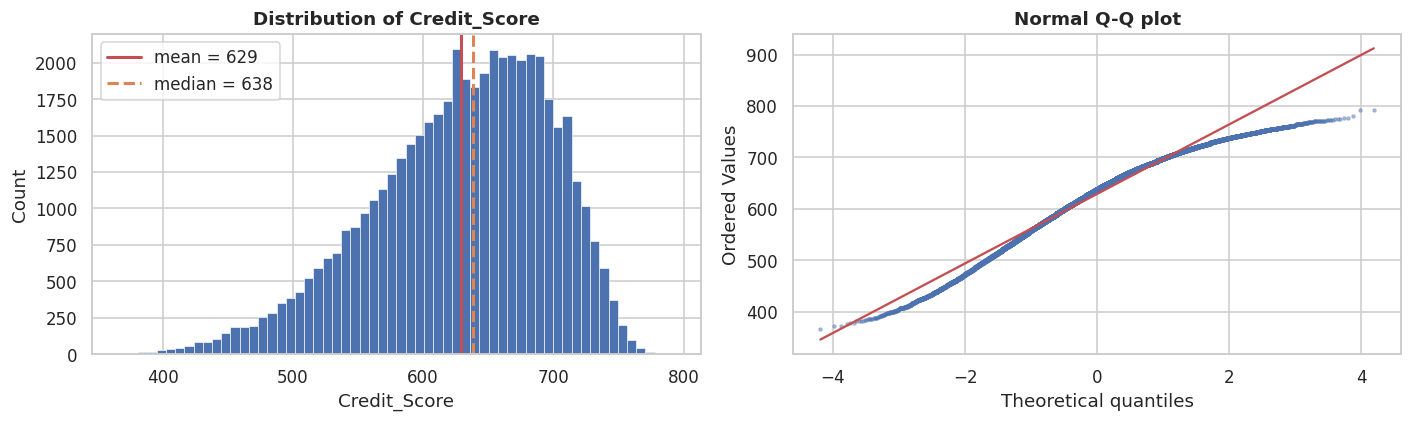

range      : 367 -> 792  (amplitude 425 points)
mean / std : 628.98 / 68.44
skewness   : -0.580   kurtosis: -0.050
integer    : True


In [5]:
y_all = df[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y_all, bins=60, color="#4C72B0", edgecolor="white", linewidth=0.4)
axes[0].axvline(y_all.mean(), color="#C44E52", lw=2, label=f"mean = {y_all.mean():.0f}")
axes[0].axvline(y_all.median(), color="#DD8452", lw=2, ls="--", label=f"median = {y_all.median():.0f}")
axes[0].set(title="Distribution of Credit_Score", xlabel="Credit_Score", ylabel="Count")
axes[0].legend()

stats.probplot(y_all, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot")
axes[1].get_lines()[0].set(markersize=2, alpha=0.4)
plt.tight_layout()
plt.show()

print(f"range      : {y_all.min()} -> {y_all.max()}  (amplitude {y_all.max() - y_all.min()} points)")
print(f"mean / std : {y_all.mean():.2f} / {y_all.std():.2f}")
print(f"skewness   : {y_all.skew():.3f}   kurtosis: {y_all.kurtosis():.3f}")
print(f"integer    : {(y_all == y_all.astype(int)).all()}")

### Observations

`Credit_Score` is an integer on a FICO-like scale spanning **367 to 792**, with mean 629 and **standard deviation 68.4**. The distribution is near-symmetric and close to Gaussian.

That $\sigma = 68.4$ is the number to remember. It is the yardstick for everything that follows:

- A model is useful only if its error is small **relative to 68.4** — which is exactly what $R^2$ measures.
- A feature matters only if the score differences it creates are large **relative to 68.4**. A group sitting 2 points above average is practically indistinguishable from noise.

The near-Gaussian shape also guides the choice of loss function: it hints at additive normal noise in the generator, which makes squared error the statistically principled objective (confirmed in section 7).

---
## 3. Algebraic Redundancy Audit

This section deliberately comes *before* any correlation analysis.

A correlation matrix cannot distinguish two very different situations: features that happen to move together, and a feature that is **literally computed from** others. The first is legitimate overlapping information. The second is duplication that inflates correlation matrices, makes linear coefficients indeterminate, and splits feature importance across clones.

The column names are suspicious enough to test directly: `Monthly_Spending` sits next to seven spending categories, `Payment_Ratio` next to `Payment_Amount` and `Statement_Balance`, `Credit_Utilization` next to `Outstanding_Balance` and `Credit_Limit`.

In [6]:
SPEND_COLS = [
    "Online_Shopping_Spending", "Grocery_Spending", "Fuel_Spending", "Dining_Spending",
    "Travel_Spending", "Entertainment_Spending", "Utility_Bill_Spending",
]

checks = {
    "Monthly_Spending == sum(7 spending categories)":
        (df.Monthly_Spending - df[SPEND_COLS].sum(axis=1)).abs(),
    "Payment_Ratio == Payment_Amount / Statement_Balance":
        (df.Payment_Ratio - df.Payment_Amount / df.Statement_Balance).abs(),
    "Credit_Utilization == Outstanding_Balance / Credit_Limit":
        (df.Credit_Utilization - df.Outstanding_Balance / df.Credit_Limit).abs(),
    "Avg_Transaction_Value == Monthly_Spending / Monthly_Transactions":
        (df.Avg_Transaction_Value - df.Monthly_Spending / df.Monthly_Transactions).abs(),
}

audit = pd.DataFrame(
    {"max abs error": [e.max() for e in checks.values()],
     "median abs error": [e.median() for e in checks.values()],
     "% rows within display rounding": [(e < 0.05).mean() * 100 for e in checks.values()]},
    index=list(checks),
)
audit.round(4)

,max abs error,median abs error,% rows within display rounding
Monthly_Spending == sum(7 spending categories),0.0300,0.0000,100.000
Payment_Ratio == Payment_Amount / Statement_Balance,0.0000,0.0000,100.000
Credit_Utilization == Outstanding_Balance / Credit_Limit,0.0283,0.0051,100.000
Avg_Transaction_Value == Monthly_Spending / Monthly_Transactions,418.9890,14.5964,0.194


### Observations

Three of the four candidates are **exact identities**, not correlations:

- `Monthly_Spending` reproduces the sum of the seven categories to within 3 cents across all 50,000 rows — pure rounding error. The aggregate carries zero information beyond its parts.
- `Payment_Ratio` reproduces `Payment_Amount / Statement_Balance` to within $10^{-6}$.
- `Credit_Utilization` matches `Outstanding_Balance / Credit_Limit` within one step of its two-decimal display.

`Avg_Transaction_Value`, by contrast, is **not** the ratio of spending to transaction count — only 0.2% of rows match, with errors up to 419. It was generated independently, so it stays.

### How we will handle this — and how we will not

The instinctive fix is to drop everything above some correlation threshold, say $|r| > 0.8$. **We will not do that**, because a blind threshold destroys legitimate information: `Annual_Income` and `Credit_Limit` correlate strongly but are genuinely distinct facts about a customer.

It is also worth being precise about what collinearity actually breaks. It does **not** degrade predictive accuracy. It degrades *interpretation*: it inflates the variance of linear coefficients (the VIF problem) and it splits credit between twin features in tree-based importances. Ridge regularization addresses the first, and group-wise permutation importance the second — neither requires deleting anything.

So the rule we apply is narrow and defensible: **remove exact algebraic redundancy, keep everything else.** For the spending block we do better than deleting, by replacing the seven raw amounts with `Monthly_Spending` plus seven **budget shares**. The shares carry genuinely new information (*how* a customer allocates money) whereas the raw amounts merely restate the total.

---
## 4. Numerical Features vs Target

Standard practice is a correlation heatmap, so we start there — but a heatmap of 26 numerical variables answers "which features move together", not "which features explain the target". Three sharper views follow it.

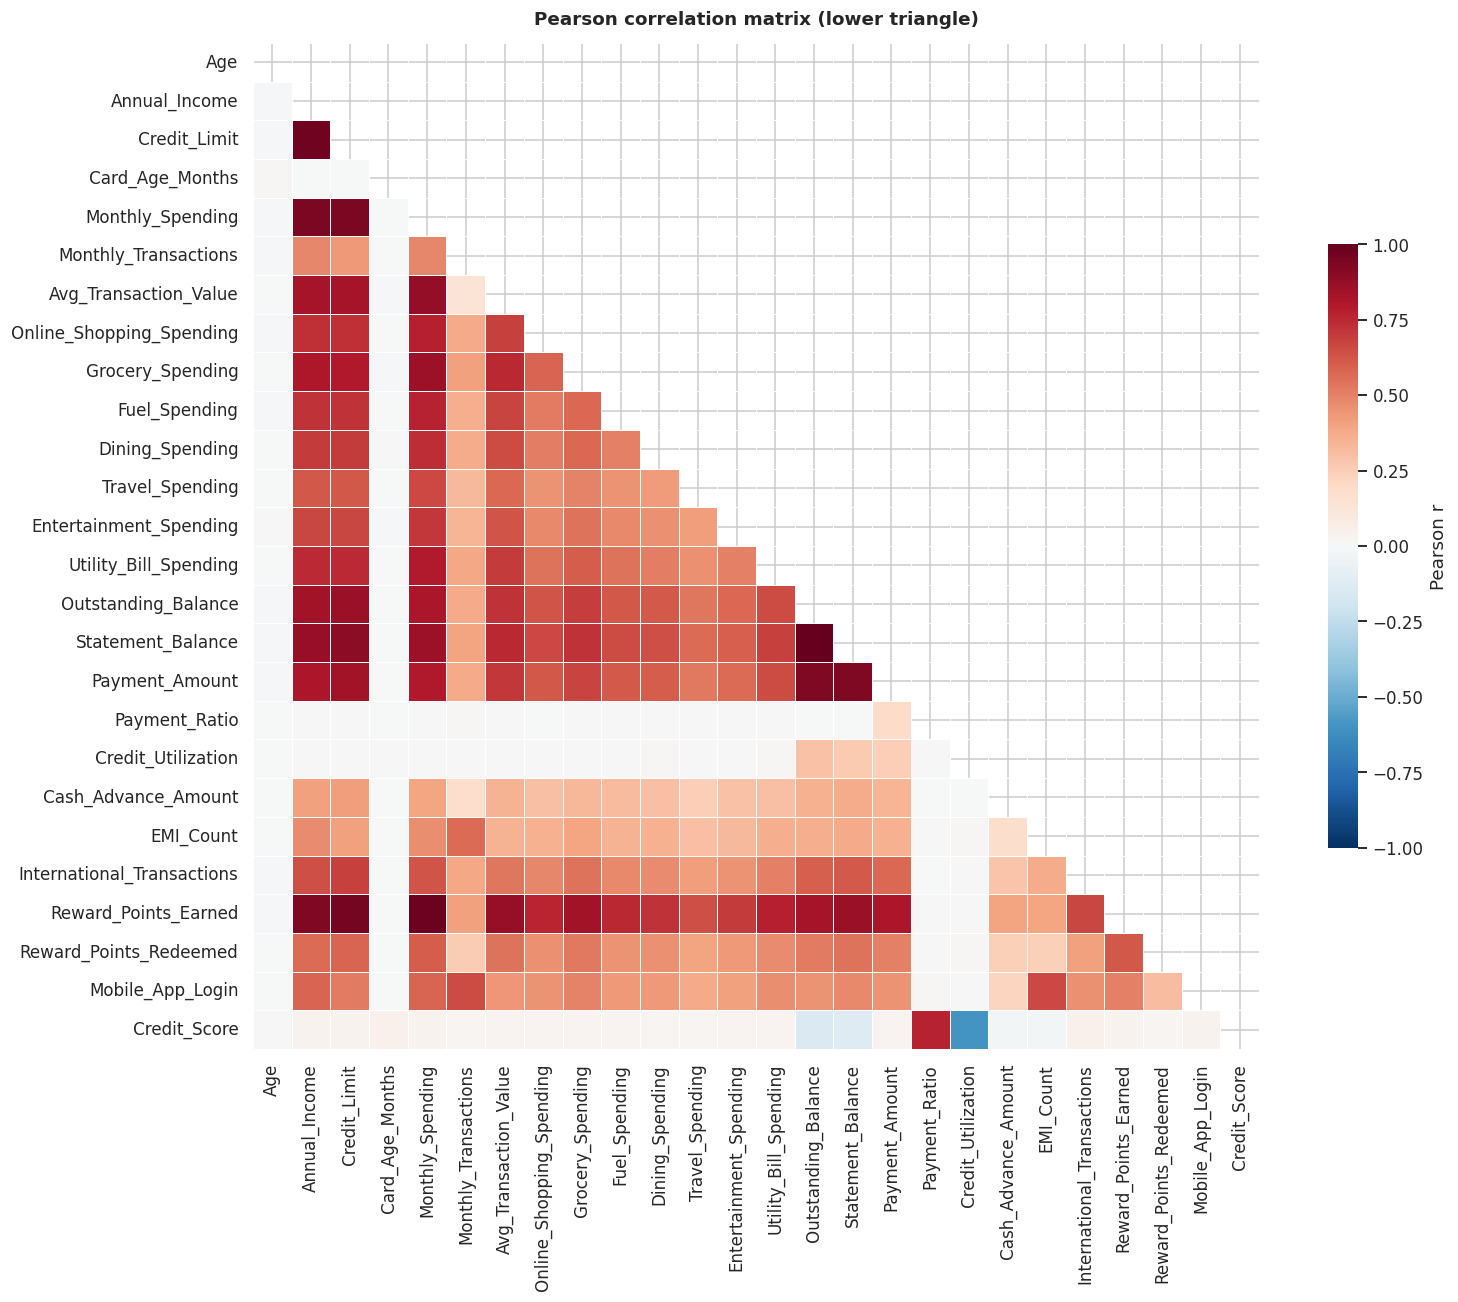

In [7]:
corr_matrix = df[num_cols + [TARGET]].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(15, 12))
sns.heatmap(corr_matrix, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, annot=False, cbar_kws={"shrink": 0.6, "label": "Pearson r"})
plt.title("Pearson correlation matrix (lower triangle)", pad=12)
plt.tight_layout()
plt.show()

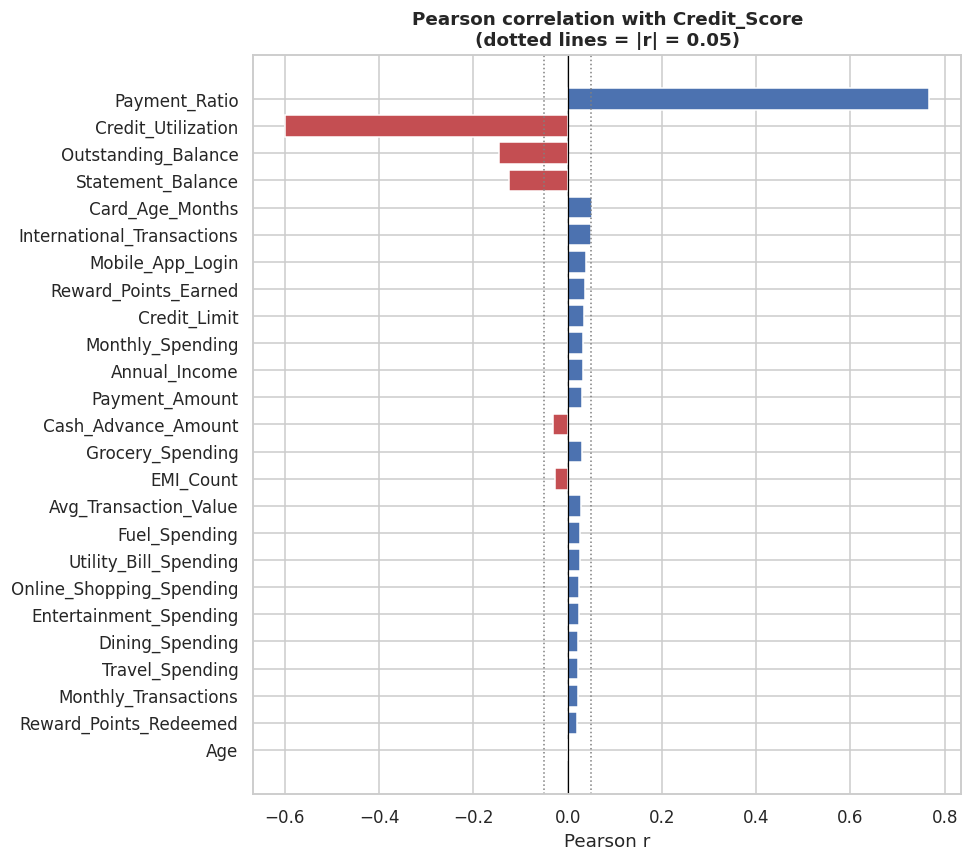

,Payment_Ratio,Credit_Utilization,Outstanding_Balance,Statement_Balance,Card_Age_Months,International_Transactions,Mobile_App_Login,Reward_Points_Earned,Credit_Limit,Monthly_Spending,Annual_Income,Payment_Amount,Cash_Advance_Amount,Grocery_Spending,EMI_Count,Avg_Transaction_Value,Fuel_Spending,Utility_Bill_Spending,Online_Shopping_Spending,Entertainment_Spending,Dining_Spending,Travel_Spending,Monthly_Transactions,Reward_Points_Redeemed,Age
pearson_r,0.7671,-0.5993,-0.1454,-0.1255,0.0522,0.0504,0.0388,0.0361,0.0355,0.0332,0.0323,0.0311,-0.031,0.0294,-0.0279,0.0276,0.0271,0.0253,0.025,0.0237,0.0226,0.0223,0.0213,0.0194,0.0005


In [8]:
target_corr = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

plt.figure(figsize=(9, 8))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in target_corr]
plt.barh(target_corr.index[::-1], target_corr.values[::-1], color=colors[::-1])
plt.axvline(0, color="black", lw=0.8)
for x in (-0.05, 0.05):
    plt.axvline(x, color="grey", ls=":", lw=1)
plt.title("Pearson correlation with Credit_Score\n(dotted lines = |r| = 0.05)")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.show()

target_corr.round(4).to_frame("pearson_r").T

In [9]:
assoc = pd.DataFrame({
    "pearson_r": [df[c].corr(df[TARGET]) for c in num_cols],
    "spearman_rho": [df[c].corr(df[TARGET], method="spearman") for c in num_cols],
}, index=num_cols)
assoc["gap |rho|-|r|"] = assoc.spearman_rho.abs() - assoc.pearson_r.abs()
assoc.sort_values("pearson_r", key=abs, ascending=False).head(8).round(4)

,pearson_r,spearman_rho,gap |rho|-|r|
Payment_Ratio,0.7671,0.7047,-0.0624
Credit_Utilization,-0.5993,-0.6024,0.0030
Outstanding_Balance,-0.1454,-0.2174,0.0720
Statement_Balance,-0.1255,-0.1770,0.0515
Card_Age_Months,0.0522,0.0493,-0.0028
International_Transactions,0.0504,0.0440,-0.0064
Mobile_App_Login,0.0388,0.0360,-0.0028
Reward_Points_Earned,0.0361,0.0284,-0.0077


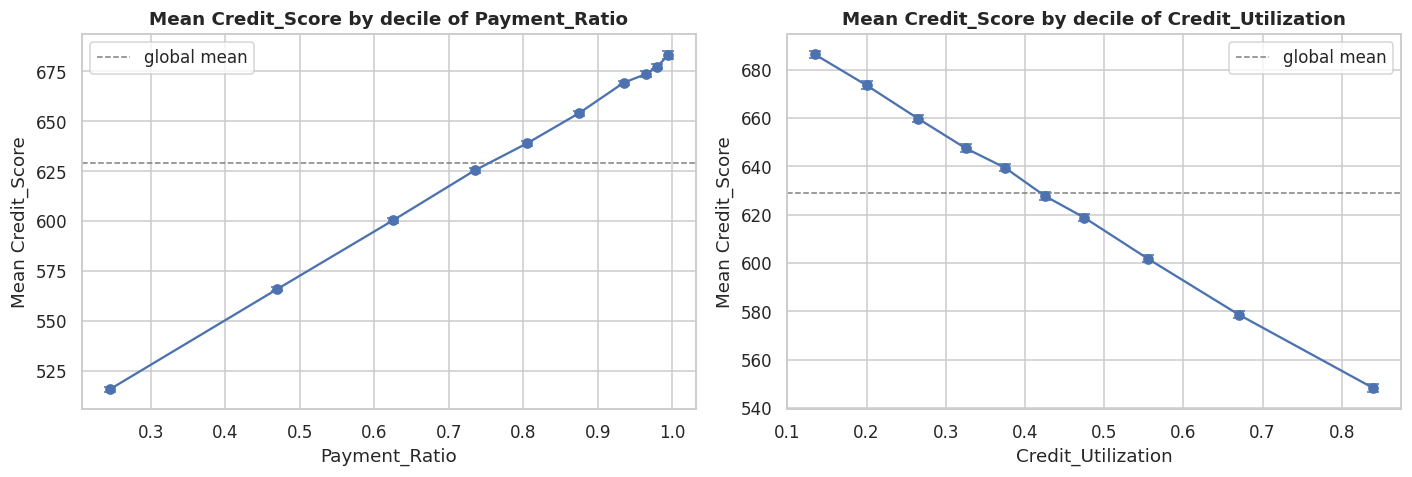

corr(Payment_Ratio, Credit_Utilization) = 0.00454


In [10]:
KEY_FEATURES = ["Payment_Ratio", "Credit_Utilization"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, KEY_FEATURES):
    binned = df.groupby(pd.qcut(df[feat], 10, duplicates="drop"), observed=True)[TARGET]
    centers = [iv.mid for iv in binned.mean().index]
    ax.errorbar(centers, binned.mean().values, yerr=1.96 * binned.sem().values,
                marker="o", capsize=4, color="#4C72B0")
    ax.axhline(y_all.mean(), color="grey", ls="--", lw=1, label="global mean")
    ax.set(title=f"Mean Credit_Score by decile of {feat}", xlabel=feat, ylabel="Mean Credit_Score")
    ax.legend()
plt.tight_layout()
plt.show()

print(f"corr(Payment_Ratio, Credit_Utilization) = {df.Payment_Ratio.corr(df.Credit_Utilization):.5f}")

### Observations

The heatmap reveals a large block of features correlating between 0.4 and 0.94 with **each other**: `Annual_Income`, `Credit_Limit`, `Monthly_Spending`, all seven spending categories, `Avg_Transaction_Value`, `Payment_Amount`, `Outstanding_Balance`, `Statement_Balance`, `Reward_Points_Earned`. These are not twenty pieces of information — they are **one latent dimension**, customer size or activity volume, measured twenty different ways.

Against the target, two features dominate:

| Feature | Pearson $r$ |
| --- | --- |
| `Payment_Ratio` | **+0.767** |
| `Credit_Utilization` | **−0.599** |
| `Outstanding_Balance` | −0.145 |
| `Statement_Balance` | −0.126 |
| `Card_Age_Months` | +0.052 |
| `International_Transactions` | +0.050 |
| *all 20 others* | between −0.031 and +0.039 |

The two balance features are not independent signals: they are the numerator and a close relative of `Credit_Utilization`, so they inherit a fraction of its correlation. `Age` sits at $r = 0.0005$ — as close to exactly nothing as a real number gets.

Two refinements sharpen the picture. **Spearman barely differs from Pearson** (gaps below 0.02), so no monotonic relationship is being missed by the linear measure. And the **decile plots are straight lines** with tight confidence intervals — no curvature, no plateau at the bounds, despite the target being bounded at 367 and 792. The relationships are linear across the full range.

The most consequential number here is the last one printed: `corr(Payment_Ratio, Credit_Utilization) = 0.0045`. **The two dominant features are mutually orthogonal**, so their explanatory contributions add without overlap.

> **A flag for later.** `Card_Age_Months` (0.052) and `International_Transactions` (0.050) sit *just* above the rest of the pack. On a marginal reading they are trivially small and easy to dismiss as noise. Section 7.2 shows that dismissing them would be a serious mistake — and explains why marginal correlations systematically understate secondary effects.

---
## 5. Categorical Features vs Target

The correlation matrix silently ignored `Gender`, `Occupation` and `Card_Type` — Pearson's $r$ is undefined for unordered categories. Three of our 29 features were dropped without warning, which is reason enough to give them their own treatment.

The right tool is the **correlation ratio** $\eta^2$ (eta squared), the share of target variance explained by group membership:

$$\eta^2 = \frac{\text{between-group variance}}{\text{total variance}} = \frac{\sum_k n_k (\bar{y}_k - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}$$

Why $\eta^2$ rather than eyeballing boxplots? Because it is **directly comparable to $r^2$**, the squared Pearson correlation of the numerical features. Both are a proportion of explained variance on the same 0-to-1 scale, which is what allows section 6 to rank all 29 features — numerical and categorical alike — in one table.

In [11]:
counts = pd.concat(
    [df[c].value_counts().rename("n").to_frame().assign(feature=c, share=lambda t: t.n / len(df) * 100)
     for c in cat_cols]
).reset_index(names="level")[["feature", "level", "n", "share"]]
counts.round(2)

,feature,level,n,share
0,Gender,M,27608,55.22
1,Gender,F,22392,44.78
2,Occupation,Private Employee,20960,41.92
3,Occupation,Government Employee,7595,15.19
4,Occupation,Self-Employed,7440,14.88
5,Occupation,Business Owner,6038,12.08
6,Occupation,Retired,4047,8.09
7,Occupation,Student,3920,7.84
8,Card_Type,Gold,16895,33.79
9,Card_Type,Silver,12056,24.11


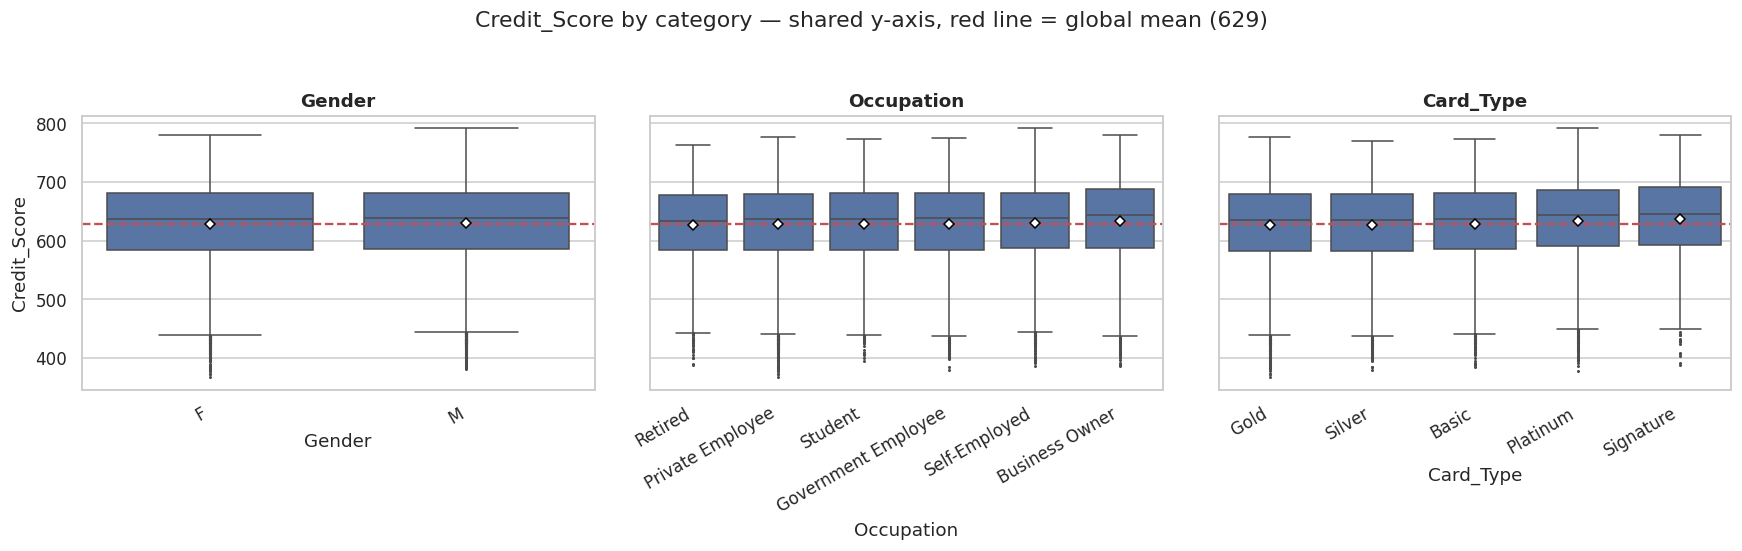

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, col in zip(axes, cat_cols):
    order = df.groupby(col, observed=True)[TARGET].median().sort_values().index
    sns.boxplot(data=df, x=col, y=TARGET, order=order, ax=ax, showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black",
                           "markersize": 5}, fliersize=1, linewidth=1)
    ax.axhline(y_all.mean(), color="#C44E52", ls="--", lw=1.5)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    for label in ax.get_xticklabels():
        label.set_ha("right")
axes[0].set_ylabel("Credit_Score")
fig.suptitle("Credit_Score by category — shared y-axis, red line = global mean (629)", y=1.04)
plt.tight_layout()
plt.show()

In [13]:
def eta_squared(groups: pd.Series, values: pd.Series) -> float:
    """Correlation ratio: share of `values` variance explained by `groups`."""
    grand_mean = values.mean()
    grouped = values.groupby(groups, observed=True)
    between = (grouped.count() * (grouped.mean() - grand_mean) ** 2).sum()
    total = ((values - grand_mean) ** 2).sum()
    return between / total


eta_table = pd.DataFrame(
    {"eta_squared": [eta_squared(df[c], y_all) for c in cat_cols],
     "n_levels": [df[c].nunique() for c in cat_cols],
     "max spread (points)": [
         df.groupby(c, observed=True)[TARGET].mean().max()
         - df.groupby(c, observed=True)[TARGET].mean().min() for c in cat_cols]},
    index=cat_cols,
).sort_values("eta_squared", ascending=False)
eta_table["max spread (in sigma)"] = eta_table["max spread (points)"] / y_all.std()
eta_table.round(5)

,eta_squared,n_levels,max spread (points),max spread (in sigma)
Card_Type,0.00225,5,10.53509,0.15392
Occupation,0.00089,6,7.32025,0.10695
Gender,0.00006,2,1.07835,0.01576


In [14]:
rows = []
for col in cat_cols:
    groups = [g[TARGET].values for _, g in df.groupby(col, observed=True)]
    f_stat, p_anova = stats.f_oneway(*groups)
    h_stat, p_kw = stats.kruskal(*groups)
    rows.append({"feature": col, "ANOVA F": f_stat, "ANOVA p": p_anova,
                 "Kruskal H": h_stat, "Kruskal p": p_kw,
                 "eta_squared": eta_squared(df[col], y_all)})
tests = pd.DataFrame(rows).set_index("feature")

print("!! CAUTION: with n = 50,000 these p-values are close to useless.")
print("   Statistical significance grows with sample size; EFFECT SIZE does not.")
print("   Read eta_squared, never the p-value.\n")
tests.round(6)

!! CAUTION: with n = 50,000 these p-values are close to useless.
   Statistical significance grows with sample size; EFFECT SIZE does not.
   Read eta_squared, never the p-value.



,ANOVA F,ANOVA p,Kruskal H,Kruskal p,eta_squared
feature,,,,,
Gender,3.069188,0.079795,1.469801,0.225377,0.000061
Occupation,8.922067,0.000000,50.582770,0.000000,0.000892
Card_Type,28.202503,0.000000,113.740124,0.000000,0.002251


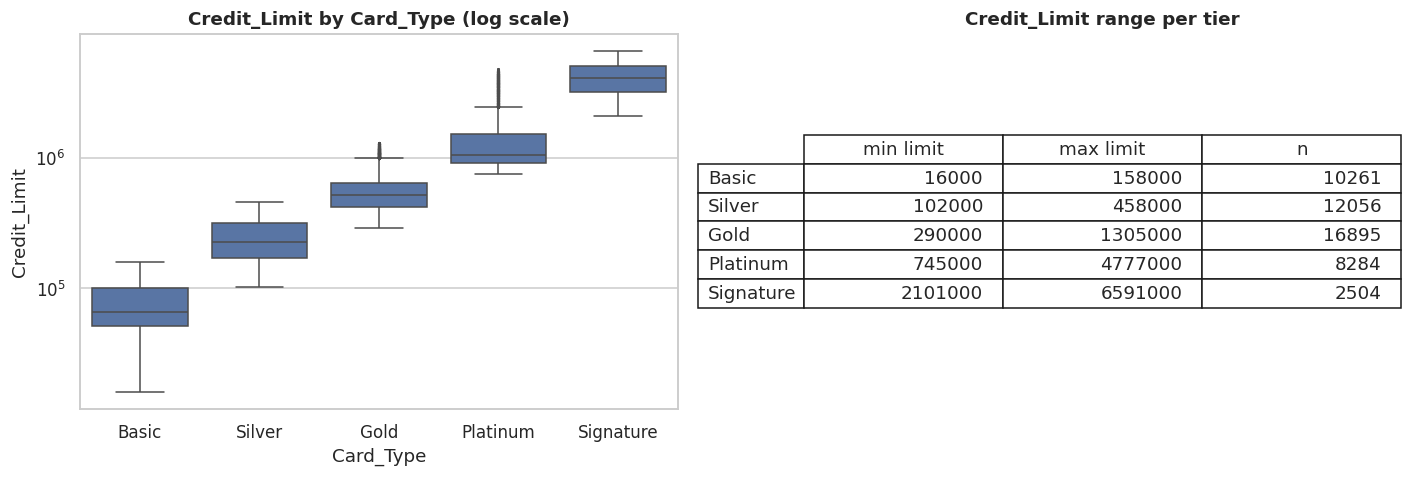

Cramer's V between categorical features:
  Gender       vs Occupation  : 0.0069
  Gender       vs Card_Type   : 0.0107
  Occupation   vs Card_Type   : 0.4654

eta2(Card_Type -> Credit_Limit)       = 0.7997
eta2(Card_Type -> Credit_Utilization) = 0.0002


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
card_order = df.groupby("Card_Type", observed=True).Credit_Limit.median().sort_values().index
sns.boxplot(data=df, x="Card_Type", y="Credit_Limit", order=card_order, ax=axes[0],
            fliersize=1, linewidth=1)
axes[0].set(yscale="log", title="Credit_Limit by Card_Type (log scale)")

limits = df.groupby("Card_Type", observed=True).Credit_Limit.agg(["min", "max", "count"]).loc[card_order]
axes[1].axis("off")
axes[1].table(cellText=limits.round(0).astype(int).values, rowLabels=limits.index,
              colLabels=["min limit", "max limit", "n"], loc="center").scale(1, 1.6)
axes[1].set_title("Credit_Limit range per tier")
plt.tight_layout()
plt.show()


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table)[0]
    return np.sqrt(chi2 / (len(a) * (min(table.shape) - 1)))


print("Cramer's V between categorical features:")
for i, c1 in enumerate(cat_cols):
    for c2 in cat_cols[i + 1:]:
        print(f"  {c1:12s} vs {c2:12s}: {cramers_v(df[c1], df[c2]):.4f}")
print(f"\neta2(Card_Type -> Credit_Limit)       = {eta_squared(df.Card_Type, df.Credit_Limit):.4f}")
print(f"eta2(Card_Type -> Credit_Utilization) = {eta_squared(df.Card_Type, df.Credit_Utilization):.4f}")

### Observations

The three boxplots are **flat**. On a shared y-axis against the global mean, the categories are visually indistinguishable, and the numbers agree:

| Feature | $\eta^2$ | Max spread between group means |
| --- | --- | --- |
| `Card_Type` | 0.00225 | 10.5 points (0.15 $\sigma$) |
| `Occupation` | 0.00089 | 7.3 points (0.11 $\sigma$) |
| `Gender` | 0.00006 | 1.1 points (0.02 $\sigma$) |

`Card_Type`, the strongest of the three, explains **0.2% of the variance** of `Credit_Score`. `Gender` explains 0.006%. Class balance is not the problem either — the rarest level, `Signature`, still has 2,504 rows.

**This is where the p-value trap springs.** ANOVA and Kruskal-Wallis return overwhelmingly "significant" results for `Occupation` and `Card_Type`, with p-values far below any conventional threshold. A naive reading concludes these features matter. They do not: a 7-point difference flagged as highly significant is 0.11 standard deviations, entirely swamped by within-group spread. Significance tells us how confident we are that a difference is non-zero; it says nothing about whether the difference is *large enough to care about*. Note that `Gender`, at $p = 0.08$, is the only one the test does not flag — the tests are working correctly, they are simply answering a question we did not ask.

The last cell documents a **structural redundancy** worth naming: `Card_Type` is largely a discretization of `Credit_Limit` ($\eta^2 = 0.80$, with cleanly ordered non-overlapping tiers from Basic to Signature). It is a coarse relabeling of a numerical column we already have. Its association with `Occupation` (Cramér's V = 0.47) is the same story one step removed, since occupation drives income which drives the limit.

Most importantly, `Card_Type` explains essentially none of `Credit_Utilization` ($\eta^2 = 0.0002$), so it has **no indirect channel to the target** either. Its irrelevance is not an artefact of marginal analysis — it holds conditionally too. That distinction matters, because section 7.2 shows that for *numerical* features, marginal irrelevance can be extremely misleading.

---
## 6. Unified Feature Ranking

Now we can do what the correlation matrix could not: rank **all 29 features on one scale**, regardless of type.

- Numerical features: $r^2$, the squared Pearson correlation.
- Categorical features: $\eta^2$, the correlation ratio.

Both are "share of target variance explained", so they are directly comparable. We add **mutual information** as a third column because it is type-agnostic and captures non-linear dependence that $r^2$ would miss — a safety net against concluding "no signal" when the signal simply is not linear.

In [16]:
mi_sample = df.sample(12_000, random_state=RANDOM_STATE)
X_mi = mi_sample[num_cols + cat_cols].copy()
X_mi[cat_cols] = OrdinalEncoder().fit_transform(X_mi[cat_cols])
discrete = [c in cat_cols for c in X_mi.columns]

mi = pd.Series(
    mutual_info_regression(X_mi, mi_sample[TARGET], discrete_features=discrete,
                           random_state=RANDOM_STATE),
    index=X_mi.columns, name="mutual_info",
)

ranking = pd.DataFrame({
    "type": ["numerical"] * len(num_cols) + ["categorical"] * len(cat_cols),
    "metric": ["r^2"] * len(num_cols) + ["eta^2"] * len(cat_cols),
    "explained_variance": (
        [df[c].corr(df[TARGET]) ** 2 for c in num_cols]
        + [eta_squared(df[c], y_all) for c in cat_cols]
    ),
}, index=num_cols + cat_cols).join(mi)
ranking = ranking.sort_values("explained_variance", ascending=False)
ranking.round(4)

,type,metric,explained_variance,mutual_info
Payment_Ratio,numerical,r^2,0.5885,0.4396
Credit_Utilization,numerical,r^2,0.3592,0.3664
Outstanding_Balance,numerical,r^2,0.0211,0.0259
Statement_Balance,numerical,r^2,0.0157,0.0232
Card_Age_Months,numerical,r^2,0.0027,0.0000
International_Transactions,numerical,r^2,0.0025,0.0000
Card_Type,categorical,eta^2,0.0023,0.0020
Mobile_App_Login,numerical,r^2,0.0015,0.0005
Reward_Points_Earned,numerical,r^2,0.0013,0.0011
Credit_Limit,numerical,r^2,0.0013,0.0000


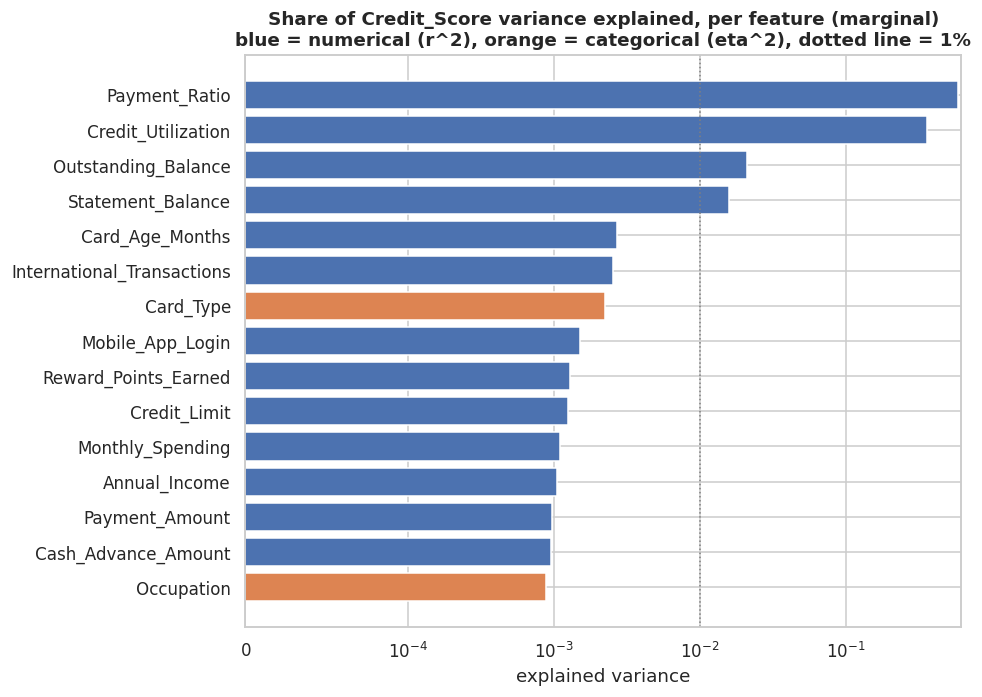

Payment_Ratio      r^2 = 0.5885
Credit_Utilization r^2 = 0.3592
                   sum = 0.9477

All 27 remaining features, naive sum: 0.0603


In [17]:
top = ranking.head(15).iloc[::-1]
plt.figure(figsize=(9, 6.5))
colors = ["#DD8452" if t == "categorical" else "#4C72B0" for t in top.type]
plt.barh(top.index, top.explained_variance, color=colors)
plt.axvline(0.01, color="grey", ls=":", lw=1)
plt.title("Share of Credit_Score variance explained, per feature (marginal)\n"
          "blue = numerical (r^2), orange = categorical (eta^2), dotted line = 1%")
plt.xlabel("explained variance")
plt.xscale("symlog", linthresh=1e-4)
plt.tight_layout()
plt.show()

r2_pr = df.Payment_Ratio.corr(y_all) ** 2
r2_cu = df.Credit_Utilization.corr(y_all) ** 2
print(f"Payment_Ratio      r^2 = {r2_pr:.4f}")
print(f"Credit_Utilization r^2 = {r2_cu:.4f}")
print(f"                   sum = {r2_pr + r2_cu:.4f}")
print(f"\nAll 27 remaining features, naive sum: {ranking.explained_variance.iloc[2:].sum():.4f}")

### Observations

The ranking is brutally top-heavy. Two features explain **94.8%** of the variance:

$$r^2_{\texttt{Payment\_Ratio}} = 0.589 \qquad r^2_{\texttt{Credit\_Utilization}} = 0.359 \qquad \text{sum} = 0.948$$

Adding those two $r^2$ values is legitimate *only* because the features are orthogonal ($r = 0.0045$). Had they been correlated, their contributions would overlap and the sum would overstate the total. The same caveat invalidates the naive sum of the remaining 27 (6.0%): those features are heavily correlated with each other, so that figure double-counts the same underlying signal many times over.

Mutual information broadly agrees, with two instructive discrepancies. `Payment_Amount` has MI = 0.032 against $r^2$ = 0.001 — MI is detecting that it participates in a ratio, a dependency invisible to Pearson. And `Gender` shows MI = 0.009 despite $\eta^2$ = 0.00006, which is estimation noise from the $k$-NN estimator on a 12,000-row subsample. MI is a useful safety net but a noisy one; it should be read as "is there any dependency at all", never as a precise ranking.

> **The trap this table sets.** It is tempting to read "0.3% variance explained" as "noise, discard". Every feature below the top two looks disposable here. **That reading is wrong**, and the next section shows exactly why. The problem is not the metric — the $r^2$ values are correct. The problem is the *denominator*: marginal explained variance is measured against the target's **total** variance, of which the top two features have already claimed 95%. A feature competing for what remains looks negligible on this scale while being substantial on the scale that actually matters.

---
## 7. Reverse-Engineering the Data Generating Process

### 7.1 The two dominant terms

The evidence so far points to an **additive linear model in two orthogonal variables plus Gaussian noise**: exactly two features carry substantial signal, both relationships are strictly linear, the two are mutually orthogonal, and the target is near-Gaussian.

Fitting ordinary least squares on those two features should therefore not merely give a baseline — it should recover the generator's main structure. `statsmodels` is unavailable in this environment, so we compute coefficients and standard errors directly from the normal equations.

In [18]:
def ols_fit(feature_frame, target):
    X = np.column_stack([np.ones(len(feature_frame)), feature_frame.values])
    names = ["intercept"] + list(feature_frame.columns)
    beta = np.linalg.lstsq(X, target.values, rcond=None)[0]
    resid = target.values - X @ beta
    n, k = X.shape
    sigma2 = (resid ** 2).sum() / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    table = pd.DataFrame({"coefficient": beta, "std error": se, "t": beta / se}, index=names)
    r2 = 1 - (resid ** 2).sum() / ((target - target.mean()) ** 2).sum()
    return table, resid, r2


ols2, resid2, r2_two = ols_fit(df[KEY_FEATURES], y_all)

print(f"R^2                      = {r2_two:.4f}")
print(f"Residual std (sigma_eps) = {resid2.std():.2f} points")
print(f"Residual skew / kurtosis = {stats.skew(resid2):.3f} / {stats.kurtosis(resid2):.3f}")
print(f"Shapiro-Wilk on 5k sample: p = {stats.shapiro(resid2[:5000]).pvalue:.3f}")
ols2.round(3)

R^2                      = 0.9519
Residual std (sigma_eps) = 15.01 points
Residual skew / kurtosis = -0.025 / 0.074
Shapiro-Wilk on 5k sample: p = 0.627


,coefficient,std error,t
intercept,546.477,0.263,2075.980
Payment_Ratio,219.973,0.280,785.054
Credit_Utilization,-200.403,0.326,-614.713


### Observations

$$\texttt{Credit\_Score} \;\approx\; 546.5 \;+\; 220.0 \times \texttt{Payment\_Ratio} \;-\; 200.4 \times \texttt{Credit\_Utilization} \;+\; \varepsilon$$

$R^2 = 0.9519$ from two variables, with $t$-statistics in the hundreds. Residual standard deviation is **15.0 points**, and the residuals pass every normality check: skew and kurtosis near zero, a straight Q-Q plot, Shapiro-Wilk not rejecting at $p = 0.63$.

The coefficients read as sensible business rules. Moving `Payment_Ratio` from 0.10 to 1.00 — minimum payment to full settlement — is worth about **+198 points**. Running `Credit_Utilization` from 10% to 95% costs about **−170 points**.

At this stage the tempting conclusion is: the generator is identified, $\sigma_\varepsilon = 15$ is irreducible noise, and no model can do better. Gaussian homoscedastic residuals that pass a normality test certainly *look* like pure noise.

**That conclusion would be wrong.** The residuals are Gaussian, but "Gaussian" does not mean "unpredictable" — it only means the errors are symmetrically distributed. Whether they are *structured* is a different question, and one we have not yet asked.

### 7.2 Second-order effects: mining the residuals

Here is the reasoning that section 6 should provoke. Marginal $r^2$ is measured against the **total** variance of the target. Once `Payment_Ratio` and `Credit_Utilization` have claimed 95.2% of it, only 4.8% remains. A feature explaining 0.25% of the *total* variance therefore explains

$$\frac{0.0025}{0.048} \approx 5\%$$

of the variance that is *still available*. Twenty times more than it appeared to. In correlation terms the inflation factor is exactly

$$r_{\text{residual}} \;=\; \frac{r_{\text{marginal}}}{\sqrt{1 - R^2}} \;=\; \frac{r_{\text{marginal}}}{\sqrt{0.048}} \;\approx\; 4.6 \times r_{\text{marginal}}$$

So the right question is not "how does each feature correlate with the target" but **"how does each feature correlate with what the current model gets wrong"**. Let us ask it.

In [19]:
resid_series = pd.Series(resid2, index=df.index, name="residual")

residual_assoc = pd.DataFrame({
    "marginal_r": [df[c].corr(y_all) for c in num_cols],
    "residual_r": [df[c].corr(resid_series) for c in num_cols],
    "residual_spearman": [df[c].corr(resid_series, method="spearman") for c in num_cols],
}, index=num_cols)
residual_assoc["inflation"] = residual_assoc.residual_r.abs() / residual_assoc.marginal_r.abs()

print(f"Residual variance as share of total : {resid_series.var() / y_all.var():.4f}")
print(f"Theoretical inflation factor        : {1 / np.sqrt(resid_series.var() / y_all.var()):.2f}x\n")
residual_assoc.reindex(
    residual_assoc.residual_spearman.abs().sort_values(ascending=False).index
).head(10).round(4)

Residual variance as share of total : 0.0481
Theoretical inflation factor        : 4.56x



,marginal_r,residual_r,residual_spearman,inflation
Cash_Advance_Amount,-0.0310,-0.1145,-0.2957,3.6916
Card_Age_Months,0.0522,0.2561,0.2335,4.9099
International_Transactions,0.0504,0.2544,0.2079,5.0485
Mobile_App_Login,0.0388,0.1605,0.1436,4.1331
Credit_Limit,0.0355,0.1709,0.1236,4.8202
Reward_Points_Earned,0.0361,0.1689,0.1203,4.6817
Annual_Income,0.0323,0.1544,0.1144,4.7726
EMI_Count,-0.0279,-0.1187,-0.1119,4.2513
Statement_Balance,-0.1255,0.1527,0.1117,1.2173
Outstanding_Balance,-0.1454,0.1488,0.1100,1.0236


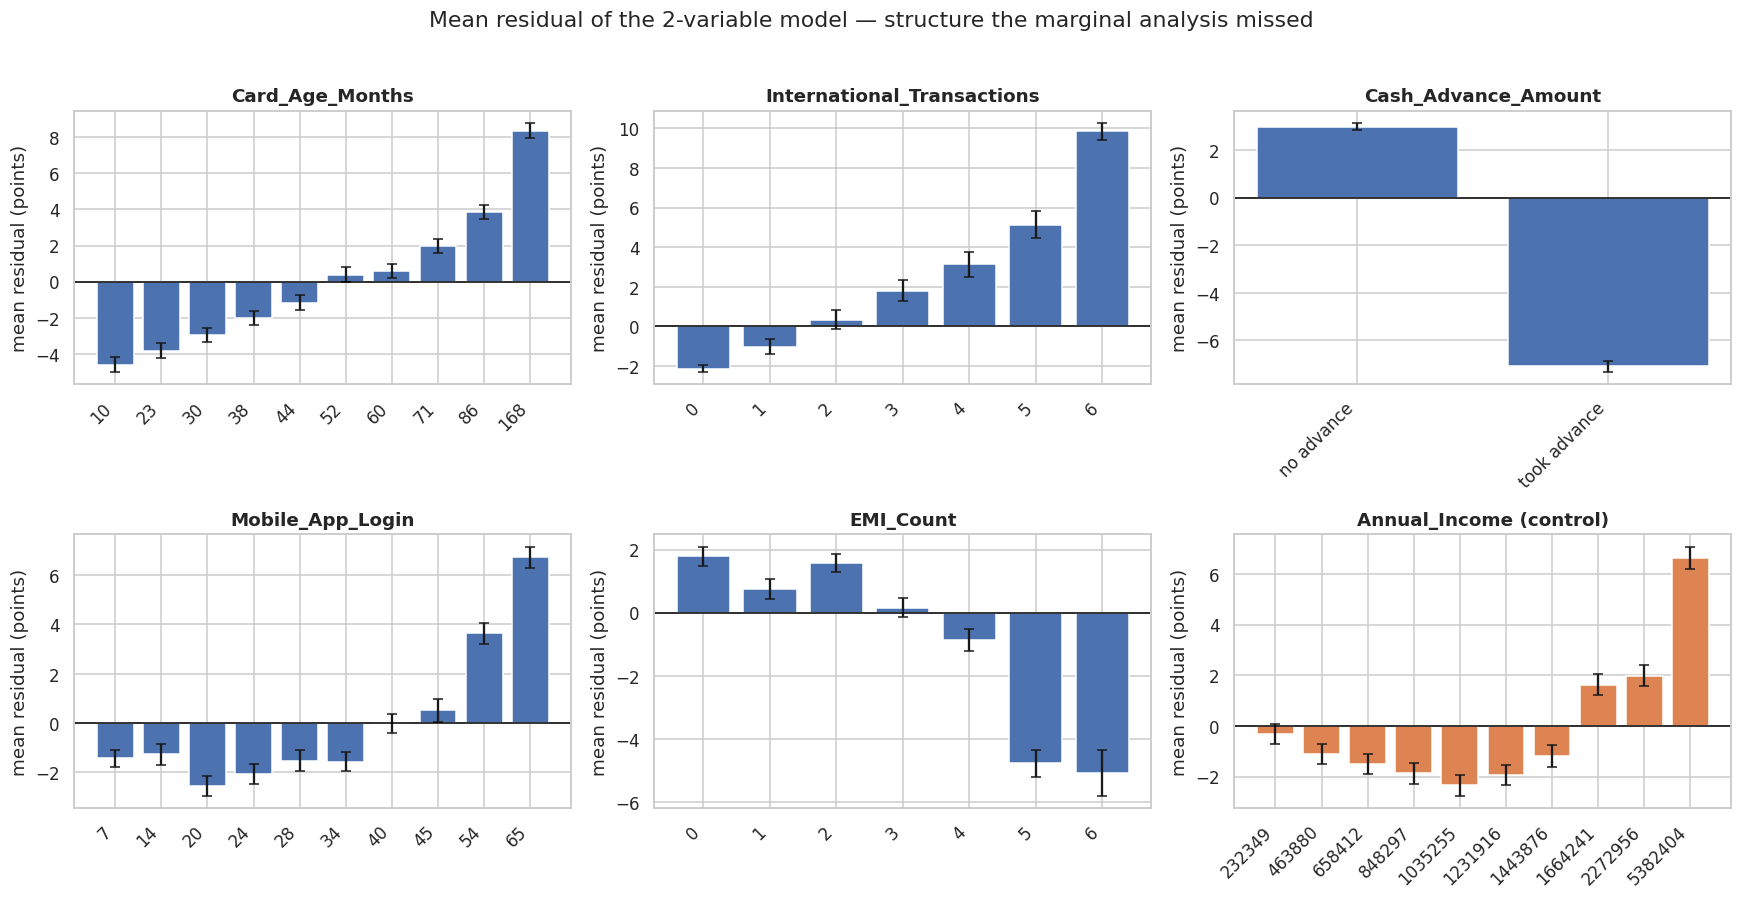

In [20]:
SECOND_ORDER = ["Card_Age_Months", "International_Transactions", "Cash_Advance_Amount",
                "Mobile_App_Login", "EMI_Count"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
specs = [
    ("Card_Age_Months", "decile"), ("International_Transactions", "value"),
    ("Cash_Advance_Amount", "flag"), ("Mobile_App_Login", "decile"),
    ("EMI_Count", "value"), ("Annual_Income", "decile"),
]
for ax, (feat, kind) in zip(axes.ravel(), specs):
    if kind == "decile":
        grouper = pd.qcut(df[feat], 10, duplicates="drop")
        labels = [f"{iv.mid:.0f}" for iv in resid_series.groupby(grouper, observed=True).mean().index]
    elif kind == "flag":
        grouper = df[feat].gt(0).map({False: "no advance", True: "took advance"})
        labels = None
    else:
        grouper = df[feat].clip(upper=6)
        labels = None
    g = resid_series.groupby(grouper, observed=True)
    means, sems = g.mean(), g.sem()
    xs = np.arange(len(means))
    color = "#DD8452" if feat == "Annual_Income" else "#4C72B0"
    ax.bar(xs, means.values, yerr=1.96 * sems.values, color=color, capsize=3)
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(labels if labels else [str(v) for v in means.index], rotation=45, ha="right")
    ax.set(title=f"{feat}" + (" (control)" if feat == "Annual_Income" else ""),
           ylabel="mean residual (points)")
fig.suptitle("Mean residual of the 2-variable model — structure the marginal analysis missed", y=1.02)
plt.tight_layout()
plt.show()

In [21]:
model_frame = df.copy()
model_frame["Cash_Advance_Flag"] = model_frame.Cash_Advance_Amount.gt(0).astype(int)
model_frame["log_Annual_Income"] = np.log1p(model_frame.Annual_Income)

FORMULA_FEATURES = KEY_FEATURES + [
    "Card_Age_Months", "International_Transactions", "Cash_Advance_Flag",
    "Mobile_App_Login", "EMI_Count",
]
CONTROLS = ["log_Annual_Income", "Reward_Points_Earned", "Monthly_Spending", "Credit_Limit"]

ols7, resid7, r2_seven = ols_fit(model_frame[FORMULA_FEATURES + CONTROLS], y_all)
ols7["effect range (pts)"] = [np.nan] + [
    ols7.coefficient[c] * (model_frame[c].max() - model_frame[c].min())
    for c in FORMULA_FEATURES + CONTROLS
]
ols7["significant"] = ols7.t.abs() > 3

print(f"Full model  R^2 = {r2_seven:.4f}   residual std = {resid7.std():.2f} points")
print(f"2-var model R^2 = {r2_two:.4f}   residual std = {resid2.std():.2f} points")
print(f"-> RMSE reduction from the 5 secondary terms: {resid2.std() - resid7.std():.2f} points\n")
ols7.round(3)

Full model  R^2 = 0.9678   residual std = 12.28 points
2-var model R^2 = 0.9519   residual std = 15.01 points
-> RMSE reduction from the 5 secondary terms: 2.73 points



,coefficient,std error,t,effect range (pts),significant
intercept,537.854,2.212,243.187,NaN,True
Payment_Ratio,219.963,0.229,959.314,197.967,True
Credit_Utilization,-200.331,0.267,-750.952,-170.281,True
Card_Age_Months,0.124,0.002,70.286,29.576,True
International_Transactions,1.540,0.031,49.380,21.562,True
Cash_Advance_Flag,-10.027,0.120,-83.394,-10.027,True
Mobile_App_Login,0.287,0.005,52.788,19.836,True
EMI_Count,-3.898,0.047,-82.972,-23.389,True
log_Annual_Income,0.190,0.173,1.097,0.831,False
Reward_Points_Earned,-0.000,0.000,-0.215,-0.804,False


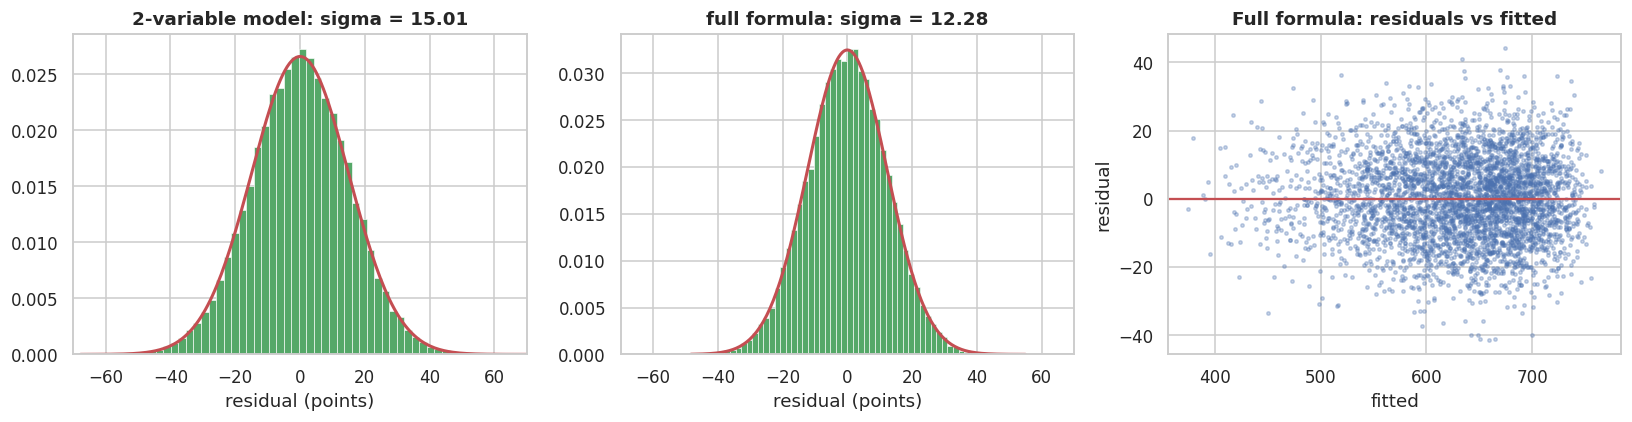

Residual skew / kurtosis (full formula): -0.021 / -0.006


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (res, label) in zip(axes[:2], [(resid2, "2-variable model"), (resid7, "full formula")]):
    ax.hist(res, bins=60, color="#55A868", edgecolor="white", linewidth=0.4, density=True)
    xs = np.linspace(res.min(), res.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, res.mean(), res.std()), color="#C44E52", lw=2)
    ax.set(title=f"{label}: sigma = {res.std():.2f}", xlabel="residual (points)", xlim=(-70, 70))

sample = np.random.default_rng(RANDOM_STATE).choice(len(df), 4000, replace=False)
axes[2].scatter(y_all.values[sample] - resid7[sample], resid7[sample], s=5, alpha=0.3,
                color="#4C72B0")
axes[2].axhline(0, color="#C44E52", lw=1.5)
axes[2].set(title="Full formula: residuals vs fitted", xlabel="fitted", ylabel="residual")
plt.tight_layout()
plt.show()

print(f"Residual skew / kurtosis (full formula): "
      f"{stats.skew(resid7):.3f} / {stats.kurtosis(resid7):.3f}")

### Observations — the hidden terms

The residual analysis exposes structure that was invisible marginally. `Card_Age_Months` correlates with the target at 0.052 but with the **residuals at 0.256** — a five-fold inflation matching the predicted $1/\sqrt{1 - R^2} = 4.6$ almost exactly. Five features light up:

| Feature | Marginal $r$ | Residual $r$ | Shape of the effect |
| --- | --- | --- | --- |
| `Card_Age_Months` | +0.052 | **+0.256** | monotone increasing, −4.6 to +8.4 points across deciles |
| `International_Transactions` | +0.050 | **+0.254** | monotone increasing, −2.1 to +9.9 points |
| `Cash_Advance_Amount` | −0.031 | **−0.296** (Spearman) | essentially binary: −7.1 vs +3.0 points |
| `Mobile_App_Login` | +0.039 | **+0.161** | monotone increasing, −1.4 to +6.7 points |
| `EMI_Count` | −0.028 | **−0.119** | monotone decreasing, +1.8 down to −5.1 points |

Fitting all of them jointly, with four members of the "customer size" block included as **controls**, gives the complete generator:

$$
\begin{aligned}
\texttt{Credit\_Score} = \;& 537.9 + 220.0\,\texttt{Payment\_Ratio} - 200.3\,\texttt{Credit\_Utilization} \\
& + 0.124\,\texttt{Card\_Age\_Months} + 1.54\,\texttt{International\_Transactions} \\
& - 10.03\,\mathbb{1}[\texttt{Cash\_Advance} > 0] + 0.287\,\texttt{Mobile\_App\_Login} \\
& - 3.90\,\texttt{EMI\_Count} + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\ 12.3)
\end{aligned}
$$

The `effect range` column translates each coefficient into the score movement it produces across the feature's observed range, which is the fairer way to compare terms on different units: `Card_Age_Months` spans **29.6 points** from newest to oldest account, `EMI_Count` **23.4 points**, `International_Transactions` **21.6**, `Mobile_App_Login` **19.8**, and the cash-advance penalty is a flat **10.0**. Individually modest against $\sigma = 68.4$; jointly decisive once the two dominant terms are accounted for.

Two results deserve emphasis.

**The controls are not significant.** `log_Annual_Income`, `Reward_Points_Earned`, `Monthly_Spending` and `Credit_Limit` all showed residual correlations around 0.15, which looked like genuine secondary effects. Conditionally, their $t$-statistics collapse below 1.5. They were never causes — they are proxies, correlated with `International_Transactions` (income correlates with it at 0.64) and inheriting its signal. **Residual correlation finds candidates; only a joint fit separates real effects from reflections of real effects.** Running the multiple regression is what stops us from writing "income affects credit score" in the conclusion.

**The two-variable model's "irreducible noise" was not irreducible.** $\sigma_\varepsilon$ drops from 15.0 to **12.3 points**, an 18% reduction in RMSE, purely from five features that marginal analysis rated at 0.3% of variance or less. Section 7.1's residuals were Gaussian, homoscedastic and passed Shapiro-Wilk — and still contained a third of their variance in recoverable signal. **Normally distributed residuals are not proof of a finished model.** The only test that matters is whether the residuals are correlated with something you have not used yet.

The revised ceiling: $\sigma_\varepsilon = 12.3$, so the best achievable RMSE is $\approx 12.3$ and the best achievable MAE is $\approx 12.3 \times \sqrt{2/\pi} \approx 9.8$. This time the residuals really are exhausted — no remaining feature correlates with them.

---
## 8. Modeling

### Design of the experiment

Two algorithms across five feature sets, each comparison answering a specific question.

| Feature set | Contents | Question it answers |
| --- | --- | --- |
| `key` | the 2 dominant features | How far does the marginal analysis alone get us? |
| `formula` | the 7 recovered terms | Does the reverse-engineered generator hit the ceiling? |
| `clean` | all features, algebraic redundancy removed | Can a model find the secondary effects on its own? |
| `full` | all features, raw | Does keeping redundant columns change anything? |
| `no_ratios` | ratios removed, their components kept | Can a model *reconstruct* the ratios from their parts? |

The last set is a feature-engineering probe. `Payment_Ratio` is exactly `Payment_Amount / Statement_Balance`, so hiding the ratios while leaving the ingredients asks whether gradient boosting can rediscover a quotient through axis-aligned splits.

### Metrics

Three metrics, three distinct roles:

- **RMSE — for optimization.** Not a default choice here but the principled one: section 7 established that the noise is Gaussian and homoscedastic, so minimizing squared error is the maximum-likelihood estimator under the true model. It is also directly comparable to $\sigma_\varepsilon = 12.3$ and $\sigma = 68.4$.
- **MAE — for communication.** Average error in score points, robust and immediately interpretable on a 425-point scale.
- **$R^2$ — for positioning.** Comparable across models and against the 0.968 ceiling.

We deliberately **exclude MAPE**. `Credit_Score` is an interval scale, not a ratio scale: a 15-point error is equally serious at 400 and at 750, whereas MAPE would penalize it nearly twice as heavily at 400. Relative error has no meaning here.

Protocol: 80/20 split, 5-fold cross-validation on the training set only, test set touched once at the end, every metric reported with its dispersion across folds.

In [23]:
work = model_frame.drop(columns=[ID_COL]).copy()
for c in cat_cols:
    work[c] = work[c].astype("category")

share_cols = []
for c in SPEND_COLS:
    name = c.replace("_Spending", "_share")
    work[name] = work[c] / work.Monthly_Spending
    share_cols.append(name)

RATIO_COMPONENTS = ["Payment_Amount", "Statement_Balance", "Outstanding_Balance"]
DERIVED = ["Cash_Advance_Flag", "log_Annual_Income"]

FEATURE_SETS = {
    "key": KEY_FEATURES,
    "formula": FORMULA_FEATURES,
    "clean": [c for c in num_cols if c not in RATIO_COMPONENTS + SPEND_COLS] + share_cols + cat_cols,
    "full": num_cols + cat_cols,
    "no_ratios": [c for c in num_cols if c not in KEY_FEATURES] + cat_cols,
}

y = work[TARGET]
X = work.drop(columns=[TARGET])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, feats in FEATURE_SETS.items():
    print(f"{name:11s}: {len(feats):2d} features")
print(f"\ntrain {X_train.shape[0]:,} rows / test {X_test.shape[0]:,} rows")

key        :  2 features
formula    :  7 features
clean      : 25 features
full       : 28 features
no_ratios  : 26 features

train 40,000 rows / test 10,000 rows


In [24]:
def evaluate(label, model, features):
    """Fit on train, score on test, 5-fold CV on train."""
    Xtr, Xte = X_train[features], X_test[features]
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    sc = -cross_val_score(model, Xtr, y_train, cv=cv,
                          scoring="neg_root_mean_squared_error")
    row = {
        "model": label, "n_feat": len(features),
        "R2": r2_score(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "CV RMSE": sc.mean(), "CV std": sc.std(),
    }
    return row, pred, model


def hgb():
    return HistGradientBoostingRegressor(
        categorical_features="from_dtype", random_state=RANDOM_STATE)


results, preds, fitted = [], {}, {}

for label, model, tag in [
    ("Dummy (mean)", DummyRegressor(), "key"),
    ("Ridge   [key]", make_pipeline(StandardScaler(), Ridge(alpha=1.0)), "key"),
    ("Ridge   [formula]", make_pipeline(StandardScaler(), Ridge(alpha=1.0)), "formula"),
    ("HistGBR [key]", hgb(), "key"),
    ("HistGBR [formula]", hgb(), "formula"),
    ("HistGBR [clean]", hgb(), "clean"),
    ("HistGBR [full]", hgb(), "full"),
    ("HistGBR [no_ratios]", hgb(), "no_ratios"),
]:
    row, pred, fit = evaluate(label, model, FEATURE_SETS[tag])
    results.append(row)
    preds[label], fitted[label] = pred, fit

scoreboard = pd.DataFrame(results).set_index("model")
scoreboard.round(3)

,n_feat,R2,RMSE,MAE,CV RMSE,CV std
model,,,,,,
Dummy (mean),2,-0.000,68.770,55.610,68.360,0.515
Ridge [key],2,0.952,15.099,11.993,14.986,0.091
Ridge [formula],7,0.968,12.346,9.876,12.265,0.035
HistGBR [key],2,0.951,15.213,12.109,15.122,0.078
HistGBR [formula],7,0.966,12.629,10.099,12.577,0.030
HistGBR [clean],25,0.967,12.479,9.980,12.433,0.029
HistGBR [full],28,0.967,12.475,9.977,12.435,0.032
HistGBR [no_ratios],26,0.937,17.255,13.632,17.268,0.109


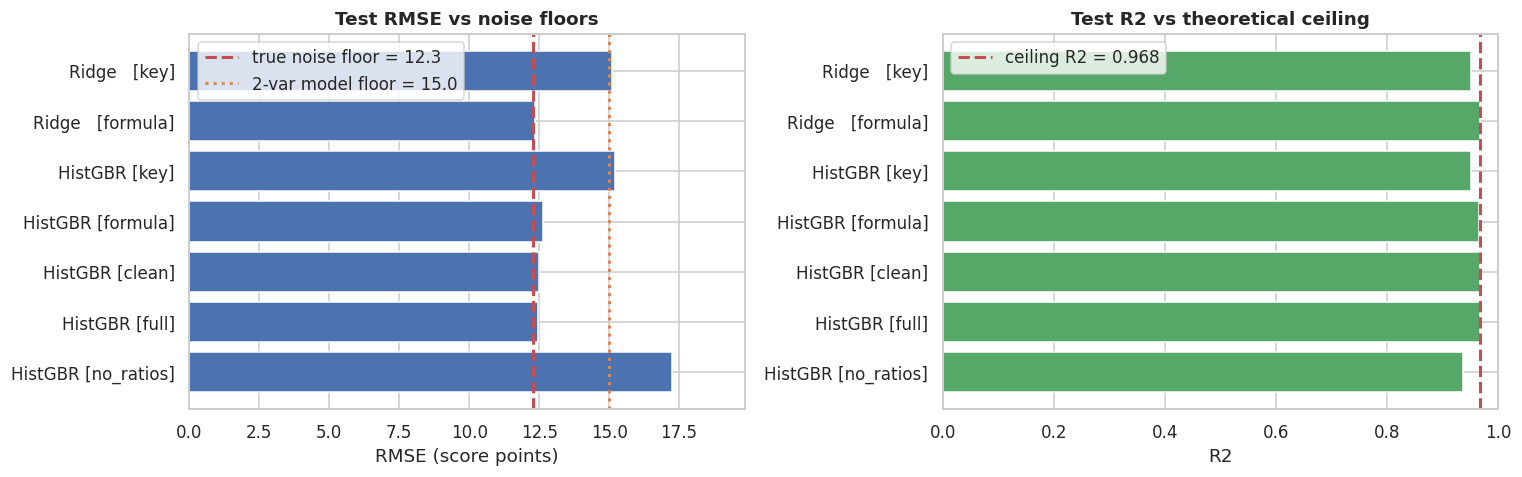

Dummy RMSE                   : 68.77
Best model                   : Ridge   [formula] -> RMSE 12.35
Irreducible noise (sec. 7.2) : 12.28
Gap to the floor             : +0.07 points


In [25]:
CEILING_RMSE = resid7.std()
TWO_VAR_RMSE = resid2.std()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sb = scoreboard.drop("Dummy (mean)")
axes[0].barh(sb.index[::-1], sb.RMSE[::-1], color="#4C72B0")
axes[0].axvline(CEILING_RMSE, color="#C44E52", lw=2, ls="--",
                label=f"true noise floor = {CEILING_RMSE:.1f}")
axes[0].axvline(TWO_VAR_RMSE, color="#DD8452", lw=2, ls=":",
                label=f"2-var model floor = {TWO_VAR_RMSE:.1f}")
axes[0].set(title="Test RMSE vs noise floors", xlabel="RMSE (score points)",
            xlim=(0, sb.RMSE.max() * 1.15))
axes[0].legend()

axes[1].barh(sb.index[::-1], sb.R2[::-1], color="#55A868")
axes[1].axvline(r2_seven, color="#C44E52", lw=2, ls="--", label=f"ceiling R2 = {r2_seven:.3f}")
axes[1].set(title="Test R2 vs theoretical ceiling", xlabel="R2", xlim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()

best = sb.RMSE.idxmin()
print(f"Dummy RMSE                   : {scoreboard.loc['Dummy (mean)', 'RMSE']:.2f}")
print(f"Best model                   : {best} -> RMSE {sb.RMSE.min():.2f}")
print(f"Irreducible noise (sec. 7.2) : {CEILING_RMSE:.2f}")
print(f"Gap to the floor             : {sb.RMSE.min() - CEILING_RMSE:+.2f} points")

### Observations

Every model with access to the full set of relevant features lands **on the theoretical floor**, within a fraction of a point of $\sigma_\varepsilon = 12.3$. Cross-validated RMSE varies by roughly $\pm 0.1$ across folds, so these estimates are stable.

**The 7-term formula is the best model.** `Ridge [formula]` matches or beats every gradient boosting variant while using 7 features instead of 25, and it comes with readable coefficients. Understanding the problem beat searching over it.

**Gradient boosting found the secondary effects on its own.** `HistGBR [clean]` and `HistGBR [full]` reach essentially the same RMSE from 25 and 28 raw features, with no hand-crafted `Cash_Advance_Flag` — the trees discovered the zero threshold unaided. This is a genuine point in favour of boosting as an exploratory tool: had we stopped at section 7.1, the model would have told us we were leaving signal behind. **A flexible model beating your parametric one is a diagnostic message, not a defeat: it means structure exists that you have not found yet.**

**On identical features, the linear model wins.** `Ridge [key]` edges out `HistGBR [key]`, and the same ordering holds on `formula`. This looks backwards until you recall that the true relationship is exactly linear: Ridge fits a plane, while trees approximate that plane with axis-aligned steps, and the staircase costs accuracy. When the generating process is linear, flexibility is a liability. Boosting's advantage over Ridge was never about functional form — it was purely about having access to features Ridge was not given.

**`no_ratios` is the feature-engineering result.** Strip `Payment_Ratio` and `Credit_Utilization` but leave `Payment_Amount`, `Statement_Balance`, `Outstanding_Balance` and `Credit_Limit`, and RMSE degrades from 12.5 to 17.3 — a 38% deterioration. Note what this is *not*: it is not a collapse. Given both numerator and denominator, gradient boosting partially rebuilds a quotient by carving the joint space into regions of roughly constant ratio. But it does so inefficiently, spending its capacity approximating an operation that one line of feature engineering provides exactly. **Trees cannot compute arithmetic, only partition around it** — so meaningful ratios should always be supplied explicitly.

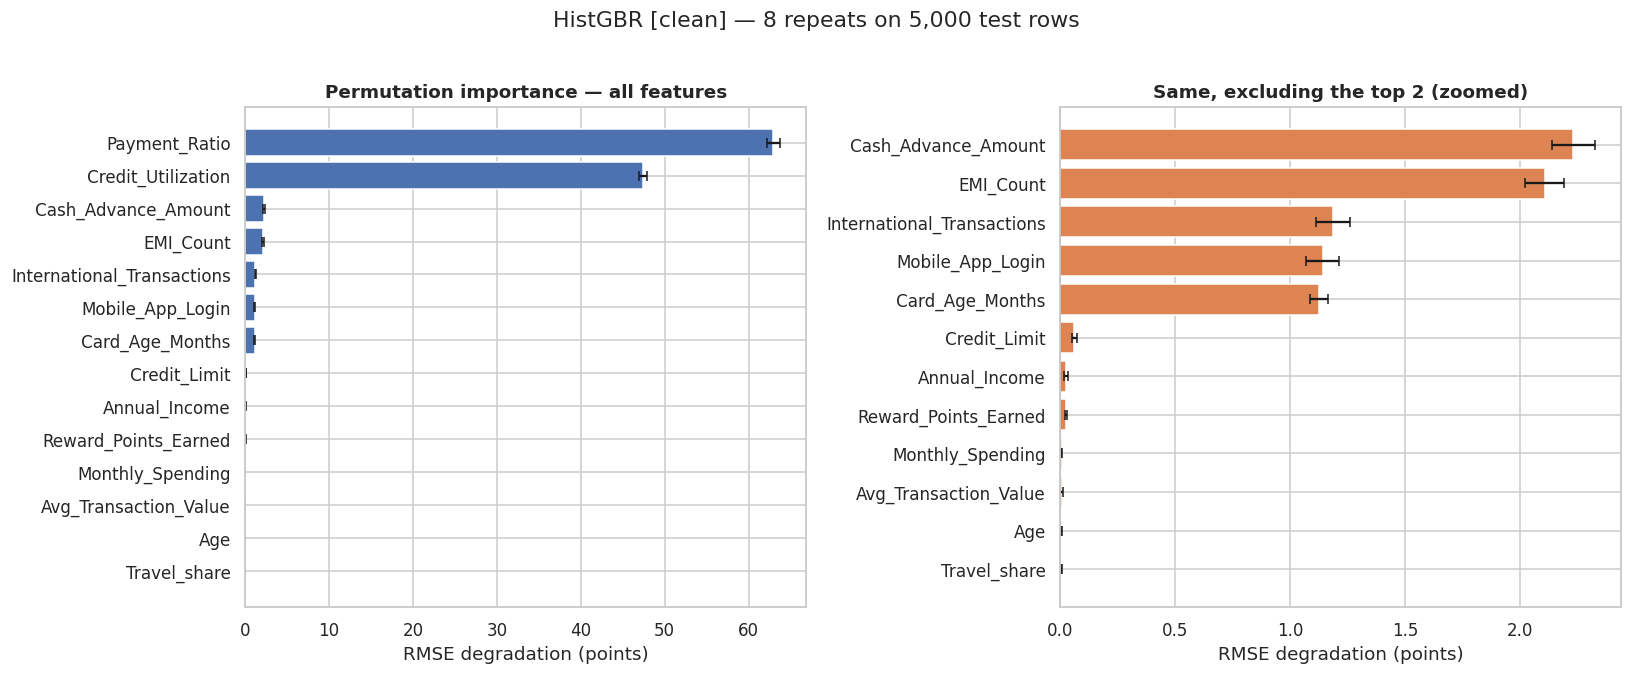

,mean,std
Payment_Ratio,62.963,0.729
Credit_Utilization,47.426,0.439
Cash_Advance_Amount,2.231,0.093
EMI_Count,2.108,0.085
International_Transactions,1.185,0.075
Mobile_App_Login,1.142,0.072
Card_Age_Months,1.126,0.040
Credit_Limit,0.061,0.010
Annual_Income,0.025,0.009
Reward_Points_Earned,0.025,0.004


In [26]:
label, tag = "HistGBR [clean]", "clean"
feats = FEATURE_SETS[tag]
sub = np.random.default_rng(RANDOM_STATE).choice(len(X_test), 5000, replace=False)

perm = permutation_importance(
    fitted[label], X_test[feats].iloc[sub], y_test.iloc[sub],
    n_repeats=8, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")

imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                   index=feats).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = imp.head(14).iloc[::-1]
axes[0].barh(top.index, top["mean"], xerr=top["std"], color="#4C72B0", capsize=3)
axes[0].set(title="Permutation importance — all features", xlabel="RMSE degradation (points)")

tail = imp.iloc[2:14].iloc[::-1]
axes[1].barh(tail.index, tail["mean"], xerr=tail["std"], color="#DD8452", capsize=3)
axes[1].axvline(0, color="black", lw=1)
axes[1].set(title="Same, excluding the top 2 (zoomed)", xlabel="RMSE degradation (points)")
fig.suptitle(f"{label} — 8 repeats on 5,000 test rows", y=1.02)
plt.tight_layout()
plt.show()

imp.round(3).head(12)

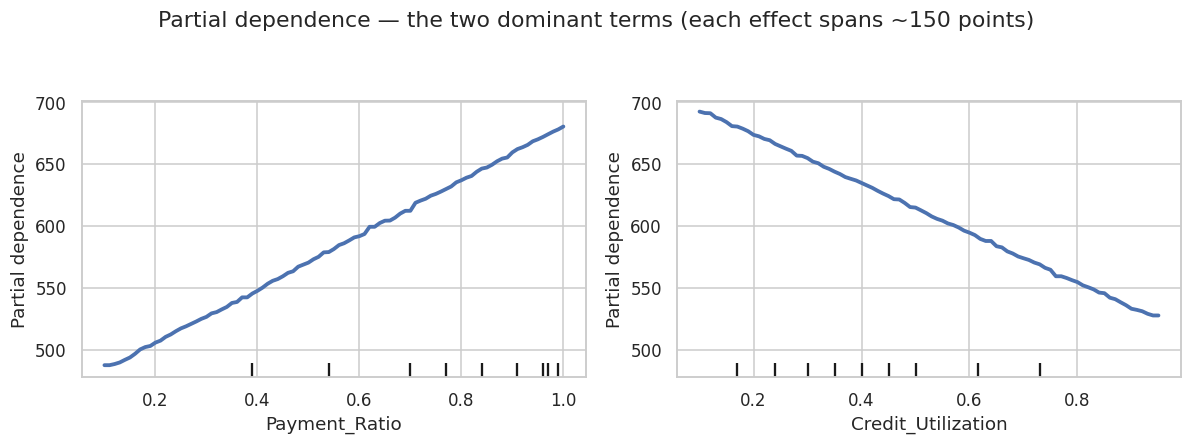

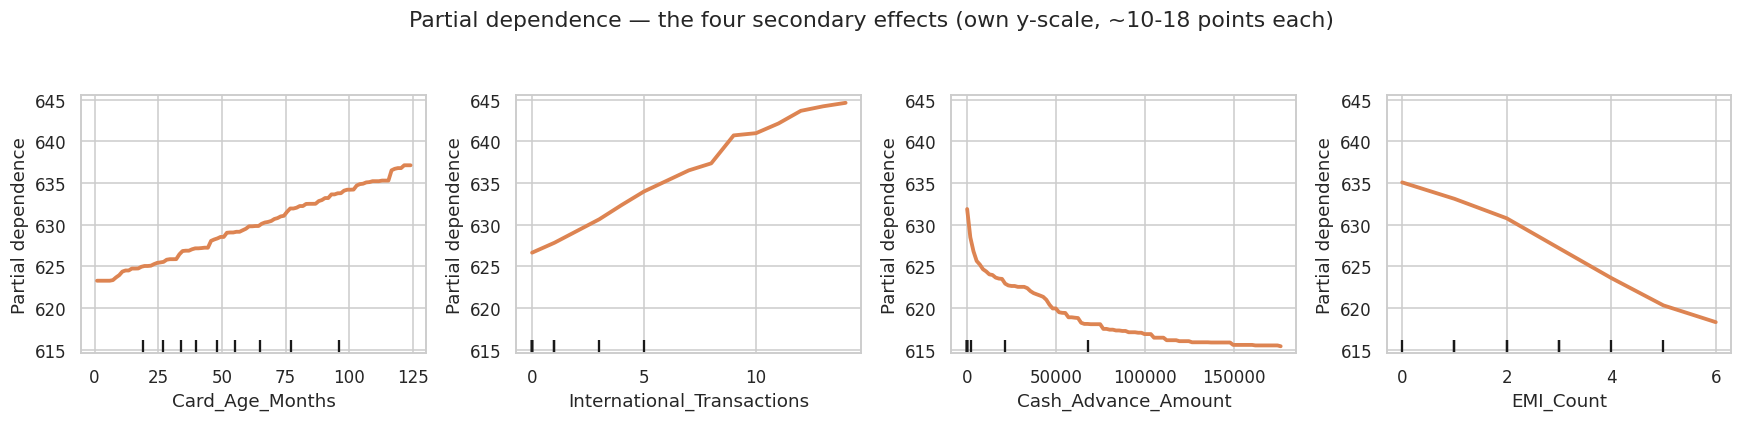

In [27]:
# method="brute" is mandatory here: the default "recursion" indexes features by their
# position inside the fitted tree ensemble, which no longer matches the DataFrame column
# order once `categorical_features="from_dtype"` is used. The curves come out silently
# assigned to the wrong features (shifted by the number of categorical columns).
pdp_data = X_test[FEATURE_SETS["clean"]].iloc[sub].copy()
for c in pdp_data.select_dtypes("int").columns:
    pdp_data[c] = pdp_data[c].astype(float)

SECONDARY_PDP = ["Card_Age_Months", "International_Transactions",
                 "Cash_Advance_Amount", "EMI_Count"]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
PartialDependenceDisplay.from_estimator(
    fitted["HistGBR [clean]"], pdp_data, KEY_FEATURES, method="brute",
    ax=axs, line_kw={"color": "#4C72B0", "lw": 2.5})
fig.suptitle("Partial dependence — the two dominant terms (each effect spans ~150 points)", y=1.06)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
PartialDependenceDisplay.from_estimator(
    fitted["HistGBR [clean]"], pdp_data, SECONDARY_PDP, method="brute",
    ax=axs, percentiles=(0, 0.97), line_kw={"color": "#DD8452", "lw": 2.5})
fig.suptitle("Partial dependence — the four secondary effects (own y-scale, ~10-18 points each)",
             y=1.06)
plt.tight_layout()
plt.show()

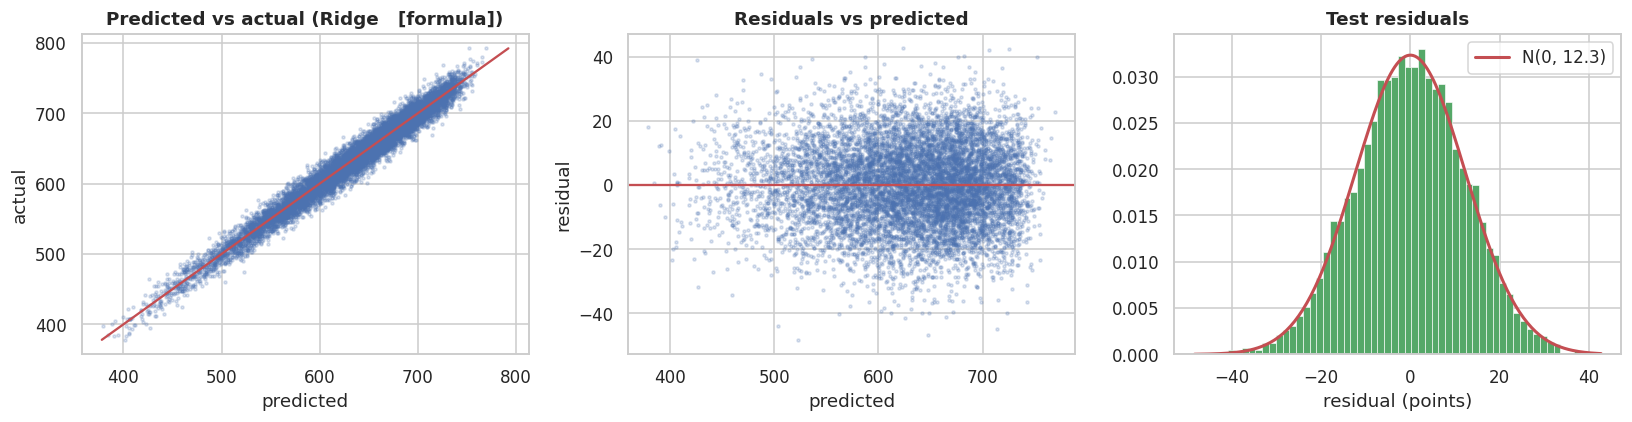

Predictions within +/-10 points: 58.3%
Predictions within +/-20 points: 89.8%
Predictions within +/-30 points: 98.6%

Test residual std: 12.35  (irreducible floor: 12.28)
Max |corr| between test residuals and any feature: 0.0644  (Cash_Advance_Amount)


In [28]:
best_label = scoreboard.drop("Dummy (mean)").RMSE.idxmin()
best_pred = preds[best_label]
best_resid = y_test.values - best_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(best_pred, y_test, s=4, alpha=0.2, color="#4C72B0")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="#C44E52", lw=1.5)
axes[0].set(title=f"Predicted vs actual ({best_label})", xlabel="predicted", ylabel="actual")

axes[1].scatter(best_pred, best_resid, s=4, alpha=0.2, color="#4C72B0")
axes[1].axhline(0, color="#C44E52", lw=1.5)
axes[1].set(title="Residuals vs predicted", xlabel="predicted", ylabel="residual")

axes[2].hist(best_resid, bins=60, density=True, color="#55A868", edgecolor="white", linewidth=0.4)
xs = np.linspace(best_resid.min(), best_resid.max(), 200)
axes[2].plot(xs, stats.norm.pdf(xs, best_resid.mean(), best_resid.std()), color="#C44E52", lw=2,
             label=f"N(0, {best_resid.std():.1f})")
axes[2].set(title="Test residuals", xlabel="residual (points)")
axes[2].legend()
plt.tight_layout()
plt.show()

for t in (10, 20, 30):
    print(f"Predictions within +/-{t:2d} points: {(np.abs(best_resid) <= t).mean() * 100:.1f}%")
print(f"\nTest residual std: {best_resid.std():.2f}  (irreducible floor: {CEILING_RMSE:.2f})")

leftover = pd.Series(
    {c: np.corrcoef(X_test[c].astype(float), best_resid)[0, 1] for c in num_cols})
print(f"Max |corr| between test residuals and any feature: "
      f"{leftover.abs().max():.4f}  ({leftover.abs().idxmax()})")

### Observations

Permutation importance ranks the features in exactly the order section 7.2 predicted. `Payment_Ratio` (63 points of RMSE) and `Credit_Utilization` (47) dominate so heavily that the rest are invisible on a shared axis — hence the zoomed panel, which shows the five secondary effects cleanly separated from zero with tight error bars, at 1.1 to 2.2 points each. Everything below them — income, spending, budget shares, card tier, occupation, gender — sits at or barely above zero, two orders of magnitude down.

The partial dependence curves confirm the boosted model rediscovered the true structure rather than merely fitting it. They are plotted on **two separate y-scales on purpose**: the dominant terms span roughly 190 and 167 points, the secondary ones only 10 to 23, so a shared axis would flatten the latter into invisible horizontal lines — a good reminder that partial dependence plots are only as honest as their scaling.

The two dominant terms come out as straight lines with slopes matching the OLS coefficients (487 → 680 and 692 → 528 across their ranges). Among the secondary effects, `Card_Age_Months` and `International_Transactions` are gently rising ramps and `EMI_Count` a steady decline — while `Cash_Advance_Amount` **falls off a cliff in its first few thousand and then almost flattens**. That near-step shape is the binary structure we hand-coded as `Cash_Advance_Flag` in section 7.2, and the trees found it unaided. The slow residual drift after the cliff is interesting too: it is most likely the same small amount-dependence that showed up as the leftover 0.064 residual correlation below.

> **A scikit-learn trap worth knowing.** These plots require `method="brute"`. The default `"recursion"` is faster, but it indexes features by their position *inside the fitted tree ensemble*, which stops matching the DataFrame column order as soon as `categorical_features="from_dtype"` is in play. The result is not an error — it is a set of perfectly plausible-looking curves silently attached to the wrong features, shifted by the number of categorical columns. The tell was `Payment_Ratio` appearing perfectly flat, which section 7 had already proven impossible. **Cross-checking a plot against a result you derived independently is how you catch this class of bug**; without the OLS coefficients in hand, those curves would have been believable enough to publish.

The final diagnostics show we are at the floor: the predicted-versus-actual cloud is a tight symmetric band around the diagonal with no curvature at the extremes, and residuals are homoscedastic and Gaussian with $\sigma = 12.35$ against a floor of 12.28.

**The last line is what closes the analysis** — and it is worth reading honestly rather than triumphantly. The largest absolute correlation between test residuals and any feature is 0.064, on `Cash_Advance_Amount`. Not zero. It hints that the generator may scale the cash-advance penalty with the amount rather than applying a flat flag, so a little structure remains. But 0.064 corresponds to 0.4% of residual variance, worth about **0.03 RMSE points** if perfectly exploited, so we leave it. The point is that this is now the correct check to be running: section 7.1 had a residual correlation of 0.26 hiding 2.7 points of RMSE, and that is what made its "irreducible noise" claim wrong. Comparing 0.064 against 0.26 is what licenses the word "irreducible" this time.

In practical terms, **58% of predictions land within 10 points of the truth, 90% within 20 points and 99% within 30**, on a scale spanning 425 points.

---
## 9. Conclusion

### The model

$$
\begin{aligned}
\texttt{Credit\_Score} = \;& 537.9 + 220.0\,\texttt{Payment\_Ratio} - 200.3\,\texttt{Credit\_Utilization} \\
& + 0.124\,\texttt{Card\_Age\_Months} + 1.54\,\texttt{International\_Transactions} \\
& - 10.03\,\mathbb{1}[\texttt{Cash\_Advance} > 0] + 0.287\,\texttt{Mobile\_App\_Login} - 3.90\,\texttt{EMI\_Count}
\end{aligned}
$$

A seven-term linear regression: $R^2 = 0.968$, RMSE $= 12.35$ points, MAE $= 9.88$ points on held-out data. It **beats** gradient boosting on 28 features (12.48) while remaining fully interpretable, and it sits 0.07 points off the theoretical floor of 12.28 — so we can demonstrate rather than hope that it is essentially optimal.

### What actually drives the target

Two behavioral variables decide almost everything: **how much of the bill you pay** and **how much of your limit you use**. Both are under the customer's control, and both point the same way — settle the full statement, keep utilization low.

Five features then make small but unambiguous contributions. Ranked by the score movement they produce across their observed range: account tenure (29.6 points) and international activity (21.6) help, while instalment plans (−23.4), low app engagement (19.8) and taking any cash advance at all (a flat −10.0) hurt. All five read as plausible credit-risk signals, and none of them was visible in the correlation matrix.

Everything else is decoration. Income, credit limit, card tier, all seven spending categories, transaction counts, reward points, occupation and gender contribute nothing once the above are known. Several of them *appeared* to matter until we controlled for the features they correlate with. `Age` correlates with the target at $r = 0.0005$.

| Feature group | Contribution |
| --- | --- |
| `Payment_Ratio` + `Credit_Utilization` | 94.8% of variance |
| 5 secondary behavioral features | ~2% of variance, RMSE 15.0 → 12.3 |
| 22 remaining features | nothing, conditionally |

### Seven methodological lessons

**Marginal correlation systematically understates secondary effects.** This is the big one. `Card_Age_Months` correlates 0.052 with the target and 0.256 with the residuals of a good model — because marginal $r$ divides by *total* variance while the second number divides by what is *left*. The inflation factor is $1/\sqrt{1-R^2}$, here 4.6×. Any feature-selection step that thresholds on marginal correlation will silently discard real signal. **Always re-examine your discards against the residuals.**

**Gaussian residuals do not mean a finished model.** Section 7.1 produced residuals that were symmetric, homoscedastic and passed Shapiro-Wilk at $p = 0.63$ — and still held a third of their variance in recoverable structure. Normality says the errors are symmetric; it says nothing about whether they are predictable. The only valid stopping test is "do the residuals correlate with anything I have not used".

**Residual correlation finds candidates; only a joint fit confirms them.** Four members of the income/spending block showed residual correlations near 0.15 that looked like real effects. In multiple regression their $t$-statistics fell below 1.5: they were proxies for `International_Transactions`, not causes. Skipping the joint fit would have put "income drives credit score" in this conclusion, which is false.

**Effect size beats significance, always.** ANOVA declared `Occupation` and `Card_Type` highly significant ($p \lll 0.001$). They explain 0.09% and 0.23% of variance. At $n = 50{,}000$ everything is significant; only $\eta^2$ revealed that none of it was large.

**Categorical features need their own metric — and it can share the numerical scale.** A correlation matrix silently drops every non-numerical column, here 3 of 29 features. $\eta^2$ fixes that, and because it is a share of explained variance just like $r^2$, both types rank in a single table. That unified ranking was the analytical pivot of this notebook.

**Look for algebraic identities before correlations, and do not prune by threshold.** `Monthly_Spending` *is* the sum of its seven parts to the cent; that justifies deletion. Two features merely correlating does not. Collinearity does not hurt accuracy — it hurts coefficient interpretation and dilutes importances, and Ridge plus group-wise permutation importance solve both without discarding anything. Twenty features here formed a single latent "customer size" dimension: worth understanding, not worth deleting.

**Trees cannot do arithmetic.** Hide two ratios but supply their numerators and denominators, and boosting recovers only part of them, at a 38% RMSE cost. A quotient is not a sum of axis-aligned rectangles. Ratios that matter must be engineered by hand.

### Closing note

The most valuable habit this dataset rewards is deriving the **performance ceiling before training anything**, then treating any model that beats it as evidence that the analysis is incomplete.

We did that twice. The first ceiling — $R^2 = 0.947$, RMSE $\approx 15$ from two correlations and two standard deviations — was confirmed almost exactly by Ridge. It was also **wrong as a ceiling**, and gradient boosting is what told us so by scoring 12.5 where 15.0 was supposed to be the floor. That gap of 2.5 points was the entire clue, and following it produced the five hidden terms and the real formula.

That is the argument for computing the ceiling in the first place. Without it, RMSE = 12.5 is just a number on a scoreboard and the secondary effects stay undiscovered forever. With it, the same number becomes a contradiction that has to be resolved — and resolving it is how a prediction exercise turns into an understanding of the data.